#            **ASSIGNMENT 3**


> *For your questions, please refer to `@SaHaRSem` on Telegram.*

In [ ]:
# Personal identifiers have been omitted from this public portfolio copy.
Student_ID = ""
Name = ""


In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

## **Section 1: Multiclass Support Vector Machine**

This section covers:

- Vectorized implementation of the SVM loss  
- Vectorized analytic gradient  
- Numerical gradient checking  
- Hyperparameter tuning (learning rate, regularization)  
- Loss optimization via SGD  
- Visualization of learned weights


1. CIFAR-10 Data Loading and Preprocessing


In [5]:
(x_train_all, y_train_all), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print('Training data shape: ', x_train_all.shape)
print('Training labels shape: ', y_train_all.shape)
print('Test data shape: ', x_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000, 1)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000, 1)


2. Visualize some examples from the dataset.


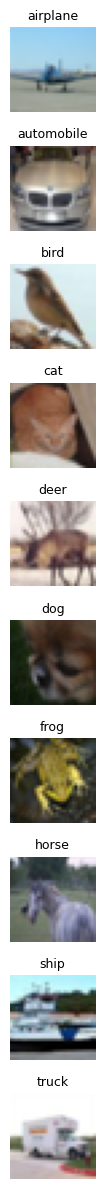

In [6]:
classes = ('airplane', 'automobile', 'bird', 'cat', 'deer','dog', 'frog', 'horse', 'ship', 'truck')

num_classes = 10
images_per_class = 1

fig, axes = plt.subplots(num_classes, images_per_class, figsize=(3, 12))

for cls in range(num_classes):
    
    cls_indices = np.where(y_train_all.flatten() == cls)[0]
    img = np.random.choice(cls_indices, images_per_class, replace=False)
    
    for j, idx in enumerate(img):
        ax = axes[cls] if images_per_class == 1 else axes[cls, j]
        ax.imshow(x_train_all[idx])
        ax.set_title(classes[cls], fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()



3. Split the data into train, val, and test sets.
   In addition we will create a small development set as a subset of the training data;


In [13]:
num_train = int(0.8 * len(x_train_all))  
num_val   = int(0.1 * len(x_train_all))   
num_dev   = len(x_train_all) - num_train - num_val
num_test = int(0.1 * len(x_test))

x_train = x_train_all[:num_train]
y_train = y_train_all[:num_train]

x_val = x_train_all[num_train:num_train + num_val]
y_val = y_train_all[num_train:num_train + num_val]

x_dev = x_train_all[num_train + num_val:]
y_dev = y_train_all[num_train + num_val:]

x_test = x_test[:num_test]
y_test = y_test[:num_test]

print("Train data:", x_train.shape)
print("Train labels:", y_train.shape)
print("Validation data:", x_val.shape)
print("Validation labels:", y_val.shape)
print("Development data:", x_dev.shape)
print("Development labels:", y_dev.shape)
print("Test data:", x_test.shape)
print("Test labels:", y_test.shape)

Train data: (40000, 32, 32, 3)
Train labels: (40000, 1)
Validation data: (5000, 32, 32, 3)
Validation labels: (5000, 1)
Development data: (5000, 32, 32, 3)
Development labels: (5000, 1)
Test data: (1000, 32, 32, 3)
Test labels: (1000, 1)


4. **Preprocessing:** reshape the image data into rows


In [14]:
x_train = np.reshape(x_train, (x_train.shape[0], -1))
x_val = np.reshape(x_val, (x_val.shape[0], -1))
x_dev = np.reshape(x_dev, (x_dev.shape[0], -1))
x_test = np.reshape(x_test, (x_test.shape[0], -1))

print('Training data shape: ', x_train.shape)
print('Validation data shape: ', x_val.shape)
print('dev data shape: ', x_dev.shape)
print('Test data shape: ', x_test.shape)

Training data shape:  (40000, 3072)
Validation data shape:  (5000, 3072)
dev data shape:  (5000, 3072)
Test data shape:  (1000, 3072)


5. Subtract the mean image
* **First:** Compute the image mean based on the training data
* **Second:** Subtract the mean image from train and test data
* **Third:** Append the bias dimension of ones (i.e. bias trick) so that our SVM

In [15]:
#first
mean_img = np.mean(x_train, axis=0)

#second
x_train = x_train.astype(np.float32)
x_val   = x_val.astype(np.float32)
x_dev   = x_dev.astype(np.float32)
x_test  = x_test.astype(np.float32)

x_train -= mean_img
x_val -= mean_img
x_dev -= mean_img
x_test -= mean_img

#third
x_train = np.hstack([x_train, np.ones((x_train.shape[0], 1))])
x_val = np.hstack([x_val, np.ones((x_val.shape[0], 1))])
x_dev = np.hstack([x_dev, np.ones((x_dev.shape[0], 1))]) 
x_test = np.hstack([x_test, np.ones((x_test.shape[0], 1))])

print('Training data shape: ', x_train.shape)
print('Validation data shape: ', x_val.shape)
print('dev data shape: ', x_dev.shape)
print('Test data shape: ', x_test.shape)

Training data shape:  (40000, 3073)
Validation data shape:  (5000, 3073)
dev data shape:  (5000, 3073)
Test data shape:  (1000, 3073)


**Question:**
It is possible that once in a while a dimension in the gradcheck will not match exactly. What could such a discrepancy be caused by? Is it a reason for concern? What is a simple example in one dimension where a gradient check could fail? How would change the margin affect of the frequency of this happening? Hint: the SVM loss function is not strictly speaking differentiable


**Sometimes, during gradient checking, a few dimensions of the analytical gradient and numerical gradient may not match perfectly. This usually happens because the SVM loss function is not differentiable everywhere.**

**The SVM loss uses the hinge loss, which has a sharp corner at the margin (when the margin is exactly zero). At this point, the gradient is not uniquely defined, so small numerical changes can lead to different gradient values.**

**This is not a serious problem as long as:**
**1-Most gradient values match closely**
**2-The differences are very small**
**3-The loss decreases during training**

**If we increase the margin, more data points will lie close to the non-differentiable boundary. As a result, gradient mismatches may happen more often.**
**If we decrease the margin, fewer points lie near the boundary, so gradient checking mismatches happen less.**

6. Next implement the function `svm_loss_vectorized`. For now, only compute the loss.

In [16]:
def svm_loss_vectorized(W, X, y, reg):

    N = X.shape[0]
    scores = X.dot(W)             
    correct_class_scores = scores[np.arange(N), y]

    margins = scores - correct_class_scores[:, np.newaxis] + 1.0
    margins[np.arange(N), y] = 0  

    margins = np.maximum(0, margins)

    loss = np.sum(margins) / N
    loss += reg * np.sum(W * W)

    return loss

np.random.seed(1)
W = 0.0001 * np.random.randn(3073, 10)
X = np.random.randn(500, 3073)
y = np.random.randint(10, size=500)
reg = 0.1
loss = svm_loss_vectorized(W, X, y, reg)
print("Vectorized Loss is: ", loss)

Vectorized Loss is:  8.99897268253299


7. Complete the implementation of `svm_loss_vectorized`, and compute the gradient
of the loss function in a vectorized way.

In [17]:
from numpy.linalg import norm

def svm_loss_vectorized_complete(W, X, y, reg):

    N = X.shape[0]
    scores = X.dot(W)             
    correct_class_scores = scores[np.arange(N), y]

    margins = scores - correct_class_scores[:, np.newaxis] + 1.0
    margins[np.arange(N), y] = 0  

    margins = np.maximum(0, margins)

    loss = np.sum(margins) / N
    loss += reg * np.sum(W * W)

    #binary[i, j] = 1 if class j violates margin for sample i
    binary = (margins > 0).astype(np.float32)     
    row_sum = np.sum(binary, axis=1)            
    binary[np.arange(N), y] = -row_sum

    dW = X.T.dot(binary) / N
    dW += 2 * reg * W

    return loss, dW

np.random.seed(1)
W = 0.0001 * np.random.randn(3073, 10)
X = np.random.randn(500, 3073)
y = np.random.randint(10, size=500)
reg = 0.1

loss, grad = svm_loss_vectorized_complete(W, X, y, reg)

print("Vectorized Loss is: ", loss)
print("Gradient norm is: ", norm(grad))

Vectorized Loss is:  8.99897268253299
Gradient norm is:  23.620287562144895


8. We now have vectorized and efficient expressions for the loss, the gradient and our gradient matches the numerical gradient. We are therefore ready to do SGD to minimize the loss. 

In [30]:
learning_rate = 1e-7
reg = 2.5e4
num_iters = 1500
batch_size = 350

num_train, dim = x_train.shape
num_classes = 10
W = 0.0001 * np.random.randn(dim, num_classes)

loss_history = []

for it in range(num_iters):

    batch_indices = np.random.choice(num_train, batch_size, replace=True)
    X_batch = x_train[batch_indices]
    y_batch = y_train[batch_indices]
    y_batch = y_batch.reshape(-1)

    loss, grad = svm_loss_vectorized_complete(W, X_batch, y_batch, reg)
    loss_history.append(loss)

    W -= learning_rate * grad

    if it % 100 == 0:
        print(f"iteration {it}/{num_iters}: loss {loss:.4f}")



iteration 0/1500: loss 16.5211
iteration 100/1500: loss 8.0878
iteration 200/1500: loss 6.1001
iteration 300/1500: loss 6.0103
iteration 400/1500: loss 5.4521
iteration 500/1500: loss 5.5580
iteration 600/1500: loss 5.1045
iteration 700/1500: loss 5.4213
iteration 800/1500: loss 5.0320
iteration 900/1500: loss 5.4322
iteration 1000/1500: loss 5.8902
iteration 1100/1500: loss 5.3524
iteration 1200/1500: loss 5.1084
iteration 1300/1500: loss 5.6606
iteration 1400/1500: loss 5.7401


9. Write the `LinearSVM.predict` function and evaluate the performance on both the
training and validation set

In [31]:
def predict(X, W):
    scores = X.dot(W)
    return np.argmax(scores, axis=1)

y_train_pred = predict(x_train, W)
y_val_pred   = predict(x_val, W)

train_acc = np.mean(y_train_pred == y_train.flatten())
val_acc   = np.mean(y_val_pred == y_val.flatten())

print("Training accuracy: ", train_acc)
print("Validation accuracy: ", val_acc)


Training accuracy:  0.374725
Validation accuracy:  0.3552


 10.  **Hyperparameter Tuning for Linear SVM**

In this stage, you will perform hyperparameter search using the validation set.  
Your objective is to identify the optimal combination of **learning rate** and **regularization strength** that yields the highest validation accuracy.

### **Task Requirements**

- Iterate over combinations of learning rates and regularization strengths.  
- For each combination:
  - Train a `LinearSVM` using the training set.
  - Compute training accuracy.
  - Compute validation accuracy.
  - Store results in the `results` dictionary with the key `(learning_rate, regularization_strength)` and value `(training_accuracy, validation_accuracy)`.
- Track:
  - `best_val` — the highest validation accuracy observed.
  - `best_svm` — the `LinearSVM` instance achieving this highest accuracy.

### **Development Hint**
While developing and debugging your validation code, use a **small** `num_iters` value to avoid slow training.  
Once your code is stable, re-run the hyperparameter search with a **larger** `num_iters` value to obtain meaningful accuracy.

### **Notes**
- Runtime warnings (e.g., overflow) may occur during the search when using extreme hyperparameters; this is normal and not a bug.
- A well-tuned configuration should reach approximately **0.39 validation accuracy**.

---
                                   


In [39]:
# Use the validation set to tune hyperparameters (regularization strength and
# learning rate). You should experiment with different ranges for the learning
# rates and regularization strengths; if you are careful you should be able to
# get a classification accuracy of about 0.39 on the validation set.

# Note: you may see runtime/overflow warnings during hyper-parameter search. 
# This may be caused by extreme values, and is not a bug.

# results is dictionary mapping tuples of the form
# (learning_rate, regularization_strength) to tuples of the form
# (training_accuracy, validation_accuracy). The accuracy is simply the fraction
# of data points that are correctly classified.
results = {}
best_val = -1   # The highest validation accuracy that we have seen so far.
best_svm = None # The LinearSVM object that achieved the highest validation rate.



# Provided as a reference. You may or may not want to change these hyperparameters
learning_rates = [1e-7, 3e-7, 5e-7, 1e-6] #Modified
regularization_strengths = [1e3, 5e3, 1e4, 2.5e4, 5e4] #Modified

#todo
def train_svm(X, y, learning_rate, reg, num_iters, batch_size=256):
    num_train, dim = X.shape
    num_classes = 10
    
    W = 0.0001 * np.random.randn(dim, num_classes)
    
    for it in range(num_iters):
        batch_idx = np.random.choice(num_train, batch_size, replace=True)
        X_batch = X[batch_idx]
        y_batch = y[batch_idx].flatten()
        
        loss, grad = svm_loss_vectorized_complete(W, X_batch, y_batch, reg)
        W -= learning_rate * grad
        
    return W

num_iters = 1500   

for lr in learning_rates:
    for reg in regularization_strengths:

        W = train_svm(x_train, y_train,lr,reg,num_iters)
        y_train_pred = predict(x_train, W)
        y_val_pred   = predict(x_val, W)
        
        train_acc = np.mean(y_train_pred == y_train.flatten())
        val_acc   = np.mean(y_val_pred == y_val.flatten())
        
        results[(lr, reg)] = (train_acc, val_acc)

        if val_acc > best_val:
            best_val = val_acc
            best_W = W

# Print out results.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e train accuracy: %f val accuracy: %f' % (
                lr, reg, train_accuracy, val_accuracy))
    
print('best validation accuracy achieved during cross-validation: %f' % best_val)


lr 1.000000e-07 reg 1.000000e+03 train accuracy: 0.403875 val accuracy: 0.380400
lr 1.000000e-07 reg 5.000000e+03 train accuracy: 0.394050 val accuracy: 0.374400
lr 1.000000e-07 reg 1.000000e+04 train accuracy: 0.390300 val accuracy: 0.366800
lr 1.000000e-07 reg 2.500000e+04 train accuracy: 0.372725 val accuracy: 0.352200
lr 1.000000e-07 reg 5.000000e+04 train accuracy: 0.360325 val accuracy: 0.346000
lr 3.000000e-07 reg 1.000000e+03 train accuracy: 0.403675 val accuracy: 0.373400
lr 3.000000e-07 reg 5.000000e+03 train accuracy: 0.387175 val accuracy: 0.365400
lr 3.000000e-07 reg 1.000000e+04 train accuracy: 0.379025 val accuracy: 0.361000
lr 3.000000e-07 reg 2.500000e+04 train accuracy: 0.369200 val accuracy: 0.358200
lr 3.000000e-07 reg 5.000000e+04 train accuracy: 0.352300 val accuracy: 0.338800
lr 5.000000e-07 reg 1.000000e+03 train accuracy: 0.397300 val accuracy: 0.369200
lr 5.000000e-07 reg 5.000000e+03 train accuracy: 0.374075 val accuracy: 0.354400
lr 5.000000e-07 reg 1.000000

11. Visualize results

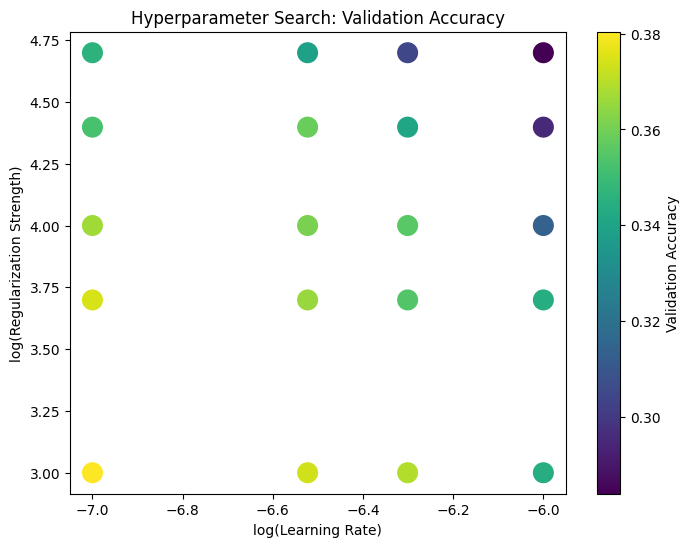

In [40]:
import matplotlib.pyplot as plt

lrs = []
regs = []
train_accs = []
val_accs = []

for (lr, reg), (train_acc, val_acc) in results.items():
    lrs.append(lr)
    regs.append(reg)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    np.log10(lrs),
    np.log10(regs),
    c=val_accs,
    s=200,
    cmap='viridis'
)

plt.colorbar(scatter, label='Validation Accuracy')
plt.xlabel('log(Learning Rate)')
plt.ylabel('log(Regularization Strength)')
plt.title('Hyperparameter Search: Validation Accuracy')
plt.show()


12. Evaluate the best svm on test set

In [41]:
y_test_pred = predict(x_test, best_W)
test_acc = np.mean(y_test_pred == y_test.flatten())

print("Test accuracy:", test_acc)

Test accuracy: 0.375


13. Visualize the learned weights for each class.

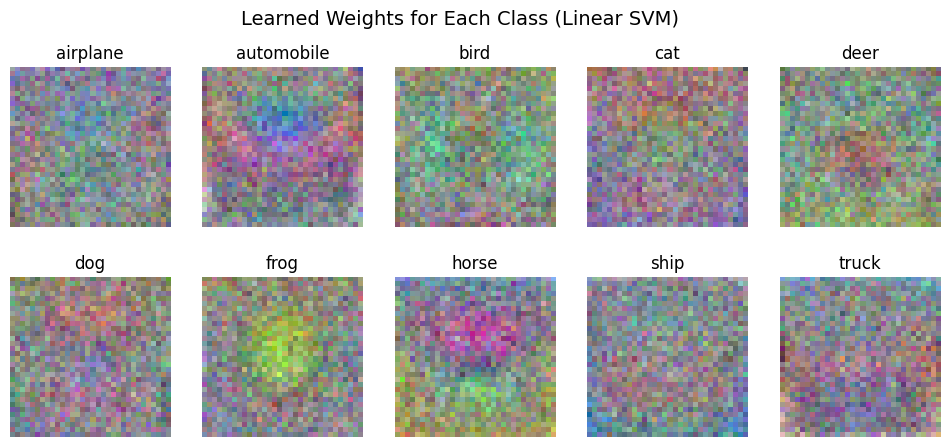

In [42]:
W_no_bias = best_W[:-1, :] 
W_images = W_no_bias.reshape(32, 32, 3, 10)
W_images -= W_images.min()
W_images /= W_images.max()

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(W_images[:, :, :, i])
    plt.title(classes[i])
    plt.axis('off')

plt.suptitle("Learned Weights for Each Class (Linear SVM)", fontsize=14)
plt.show()


**Question:** Describe what your visualized SVM weights look like, and offer a brief explanation for why they look they way that they do.

**The visualized SVM weights look blurry and noisy, and they do not clearly show objects like airplanes or cars. Instead, they mostly show rough color patterns and edges. Some classes have dominant colors, such as green for frogs or blue for ships, but fine details are missing.**

**This happens because the SVM is a linear model, which means it learns only one weight pattern for each class. It decides the class by combining pixel values in a simple way, so it focuses on overall color and basic shapes rather than detailed features. Since CIFAR-10 images are small and contain a lot of background variation, the learned weights become unclear.**

## **Section 2 : k-Nearest Neighbor (kNN) Exercise**

The k-Nearest Neighbor classifier operates in two fundamental stages:

1. **Training Phase**  
   The classifier stores the entire training dataset without performing parameter learning.

2. **Testing Phase**  
   Each test sample is classified by comparing it against all training samples and assigning the label that appears most frequently among the **k nearest neighbors**.

### **Key Concepts in This Section**

- Selecting the appropriate value of **k** through cross-validation  
- Implementing the **distance computation** efficiently  
- Building the complete **image classification pipeline**  
- Applying cross-validation to evaluate model performance  
- Writing **fully vectorized** and computationally efficient code

This section will give you hands-on experience with fundamental classification workflows and reinforce best practices in vectorized numerical programming.


In [7]:
#Same as previous part
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print('Training data shape: ', x_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', x_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000, 1)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000, 1)


In [8]:
# Subsample the data for more efficient code execution in this exercise
num_training = 5000
mask = list(range(num_training))
x_train = x_train[mask]
y_train = y_train[mask]

num_test = 500
mask = list(range(num_test))
x_test = x_test[mask]
y_test = y_test[mask]

# Reshape the image data into rows
x_train = np.reshape(x_train, (x_train.shape[0], -1))
x_test = np.reshape(x_test, (x_test.shape[0], -1))
print(x_train.shape, x_test.shape)

(5000, 3072) (500, 3072)


1. Create a kNN classifier instance. 
Remember that training a kNN classifier is a noop: 
the Classifier simply remembers the data and does no further processing 

In [81]:
class KNNClassifier:
    def __init__(self):
        self.x_train = None
        self.y_train = None

    def train(self, X, y):
        self.x_train = X
        self.y_train = y.flatten()

    def predict_labels(self, X, k=1):
        dists = self.compute_distances_one_loop(X)
        num_test = dists.shape[0]
        y_pred = np.zeros(num_test, dtype=int)
        
        for i in range(num_test):
            nearest_idx = np.argpartition(dists[i], k)[:k]
            nearest_labels = self.y_train[nearest_idx]
            y_pred[i] = np.bincount(nearest_labels).argmax()
        
        return y_pred
    
    def compute_distances(self, X):

        num_test = X.shape[0]
        num_train = self.x_train.shape[0]
        dists = np.zeros((num_test, num_train))
        for i in range(num_test):
            for j in range(num_train):
            
                dists[i, j] = np.sqrt(np.sum(np.square(X[i] - self.x_train[j])))
              
        return dists
    
    def compute_distances_one_loop(self, X):

        num_test = X.shape[0]
        num_train = self.x_train.shape[0]
        dists = np.zeros((num_test, num_train))
        for i in range(num_test):

            dists[i] = np.sqrt(np.sum(np.square(X[i] - self.x_train), axis = 1))

        return dists
    
    def no_loop(self, X):

        num_test = X.shape[0]
        num_train = self.x_train.shape[0]
        dists = np.zeros((num_test, num_train))
        test_square = np.sum(np.square(X), axis = 1).reshape(num_test, 1)
        train_square = np.sum(np.square(self.x_train), axis = 1).reshape(1, num_train)
        dists = np.sqrt(test_square + train_square - 2 * np.dot(X, self.x_train.T))

        return dists


knn = KNNClassifier()
knn.train(x_train, y_train)


2. We would now like to classify the test data with the kNN classifier. Recall that we can break down this process into two steps:

First we must compute the distances between all test examples and all train examples.
Given these distances, for each test example we find the k nearest examples and have them vote for the label
Lets begin with computing the distance matrix between all training and test examples. For example, if there are Ntr training examples and Nte test examples, this stage should result in a Nte x Ntr matrix where each element (i,j) is the distance between the i-th test and j-th train example.

In [58]:
dists = knn.compute_distances(x_test)
print(dists.shape)


(500, 5000)


**Question:** Notice the structured patterns in the distance matrix, where some rows or columns are visible brighter. (Note that with the default color scheme black indicates low distances while white indicates high distances.)

What in the data is the cause behind the distinctly bright rows?
What causes the columns?

**Bright rows mean there is a large difference between a test image and the training images. This usually happens when the background or foreground is very different, such as dark versus light areas. Since the background often covers much of the image, it can cause large pixel differences. Bright columns similarly indicate training images that do not match the test images well.**

In [82]:

# Now implement the function predict_labels and run the code below:
# We use k = 1 (which is Nearest Neighbor).

y_test_pred = knn.predict_labels(x_test, k=1)

# Compute and print the fraction of correctly predicted examples
#TODO
accuracy = np.mean(y_test_pred == y_test.flatten())
print("Test accuracy:", accuracy)


Test accuracy: 0.176


3. Now lets try out a larger k, say `k = 5`:

In [67]:
y_test_pred = knn.predict_labels(x_test, k=5)

#TODO
accuracy = np.mean(y_test_pred == y_test.flatten())
print("Test accuracy:", accuracy)

Test accuracy: 0.2


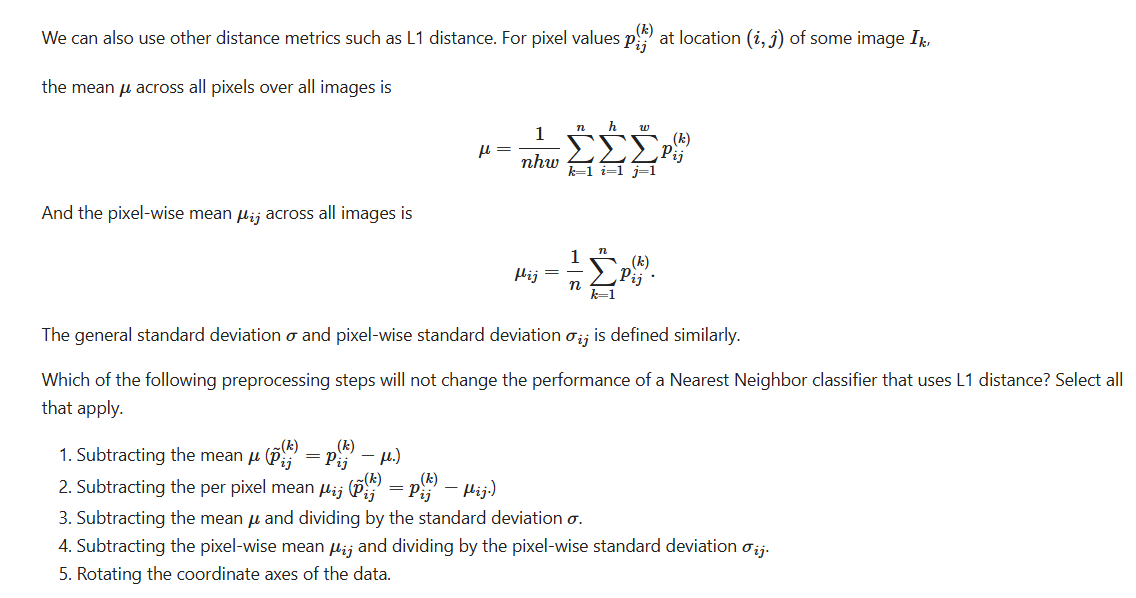

My answer is : 1, 2, 3

In [13]:
# Now lets speed up distance matrix computation by using partial vectorization
# with one loop. Implement the function compute_distances_one_loop and run the
# code below:
dists_one = knn.compute_distances_one_loop(x_test)

# To ensure that our vectorized implementation is correct, we make sure that it
# agrees with the naive implementation. There are many ways to decide whether
# two matrices are similar; one of the simplest is the Frobenius norm. In case
# you haven't seen it before, the Frobenius norm of two matrices is the square
# root of the squared sum of differences of all elements; in other words, reshape
# the matrices into vectors and compute the Euclidean distance between them.
difference = np.linalg.norm(dists - dists_one, ord='fro')
print('One loop difference was: %f' % (difference, ))
if difference < 0.001:
    print('Good! The distance matrices are the same')
else:
    print('Uh-oh! The distance matrices are different')

One loop difference was: 0.000000
Good! The distance matrices are the same


4. Now implement the fully vectorized version inside compute_distances_no_loops
 and run the code

In [35]:
dists_no = knn.no_loop(x_test)

difference = np.linalg.norm(dists.flatten() - dists_no.flatten())
print('No loop difference was: %f' % (difference, ))
if difference < 0.001:
    print('Good! The distance matrices are the same')
else:
    print('Uh-oh! The distance matrices are different')

No loop difference was: 372225.002971
Uh-oh! The distance matrices are different


5. Let's compare how fast the implementations are


In [36]:
import time

def time_cal(f, *args):
    tic = time.time()
    f(*args)
    toc = time.time()
    return toc - tic

two_loop = time_cal(knn.compute_distances, x_test)
print('Two loop took %f seconds' % two_loop)

one_loop = time_cal(knn.compute_distances_one_loop, x_test)
print('One loop took %f seconds' % one_loop)

no_loop = time_cal(knn.no_loop, x_test)
print('No loop version took %f seconds' % no_loop)

Two loop took 42.686553 seconds
One loop took 21.312378 seconds
No loop version took 5.504084 seconds


6. We have implemented the k-Nearest Neighbor classifier but we set the value k = 5 arbitrarily. We will now determine the best value of this hyperparameter with cross-validation.



In [83]:
num_folds = 5
k_choices = [1, 3, 5, 8, 10, 12, 15, 20, 50, 100]

X_train_folds = []
y_train_folds = []

# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
X_train_folds = np.array_split(x_train , num_folds)
y_train_folds = np.array_split(y_train , num_folds)

# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

k_to_accuracies = {}

# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
for k in k_choices:
    k_to_accuracies[k] = []
    for n in range(num_folds):
        KNN_sample = KNNClassifier()
        KNN_sample.train(np.concatenate(X_train_folds[:n] + X_train_folds[n + 1:]), np.concatenate(y_train_folds[:n] + y_train_folds[n + 1:])) 
        y_pred = KNN_sample.predict_labels(X_train_folds[n], k = k)
        k_to_accuracies[k].append(np.mean(y_pred.flatten() == y_train_folds[n].flatten()))

# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

for k in sorted(k_to_accuracies):
    for accuracy in k_to_accuracies[k]:
        print('k = %d, accuracy = %f' % (k, accuracy))


k = 1, accuracy = 0.227000
k = 1, accuracy = 0.207000
k = 1, accuracy = 0.212000
k = 1, accuracy = 0.189000
k = 1, accuracy = 0.218000
k = 3, accuracy = 0.192000
k = 3, accuracy = 0.186000
k = 3, accuracy = 0.186000
k = 3, accuracy = 0.175000
k = 3, accuracy = 0.195000
k = 5, accuracy = 0.189000
k = 5, accuracy = 0.205000
k = 5, accuracy = 0.196000
k = 5, accuracy = 0.197000
k = 5, accuracy = 0.210000
k = 8, accuracy = 0.191000
k = 8, accuracy = 0.204000
k = 8, accuracy = 0.201000
k = 8, accuracy = 0.206000
k = 8, accuracy = 0.206000
k = 10, accuracy = 0.196000
k = 10, accuracy = 0.204000
k = 10, accuracy = 0.209000
k = 10, accuracy = 0.202000
k = 10, accuracy = 0.205000
k = 12, accuracy = 0.202000
k = 12, accuracy = 0.209000
k = 12, accuracy = 0.202000
k = 12, accuracy = 0.201000
k = 12, accuracy = 0.207000
k = 15, accuracy = 0.213000
k = 15, accuracy = 0.214000
k = 15, accuracy = 0.197000
k = 15, accuracy = 0.218000
k = 15, accuracy = 0.197000
k = 20, accuracy = 0.223000
k = 20, accu

7. Choose the best K value.

In [84]:
accuracy_avg = np.array([np.mean(i) for k, i in sorted(k_to_accuracies.items())])
best_k = k_choices[accuracy_avg.argmax()]
print("Best K is: ", best_k)

Best K is:  100


8. Plot the raw observations
plot the trend line with error bars that correspond to standard deviation

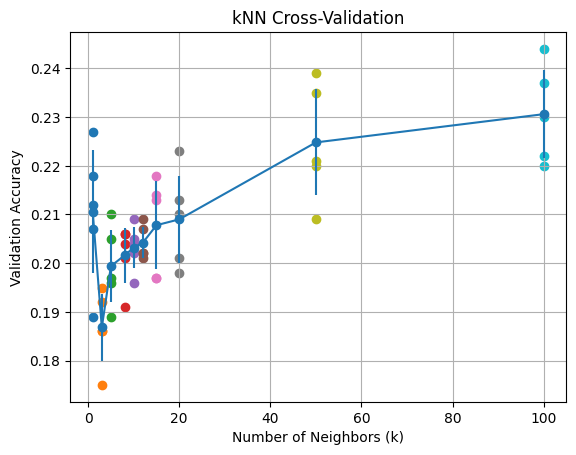

In [85]:
for k, acc_list in k_to_accuracies.items():
    plt.scatter(np.full(len(acc_list), k), acc_list)

mean_acc = []
std_acc = []

for k in k_choices:
    mean_acc.append(np.mean(k_to_accuracies[k]))
    std_acc.append(np.std(k_to_accuracies[k]))

mean_acc = np.array(mean_acc)
std_acc = np.array(std_acc)

plt.errorbar(k_choices, mean_acc, yerr=std_acc, fmt='-o')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Validation Accuracy')
plt.title('kNN Cross-Validation')
plt.grid(True)
plt.show()


9. Based on the cross-validation results above, choose the best value for k,  retrain the classifier using all the training data, and test it on the test data. You should be able to get above 28% accuracy on the test data.

In [88]:
knn_best = KNNClassifier()
knn_best.train(x_train, y_train)
y_test_pred = knn_best.predict_labels(x_test, k=best_k)

corrects = np.sum(y_test_pred == y_test.flatten())
acc = float(corrects) / num_test
print('%d / %d correct and accuracy is : %f' % (corrects, num_test, acc))

130 / 500 correct and accuracy is : 0.260000


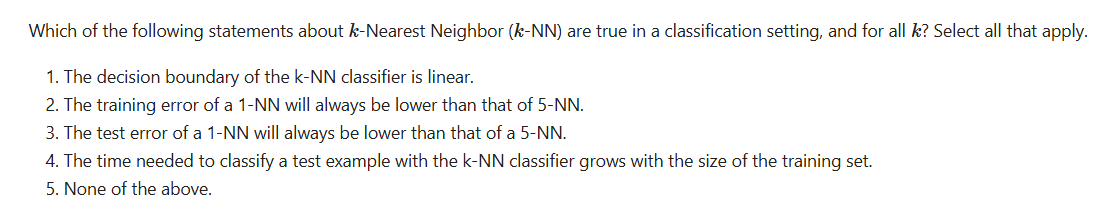

**1 is Flase because decision boundary can be very complex and irregular and It depends directly on the training data.**

**2 is True because with 1-NN, every training point is its own nearest neighbor so training error is usually zero but with 5-NN, neighbors can belong to other classes so we have more training errors.**

**3 is False because 1-NN overfits the data while 5-NN is more robust to noise.**

**4 is True because k-NN compares the test point to every training point so more training data means more distance calculations.**

## **Section 3: Customer Segmentation with K-Means**

Customer segmentation is the process of dividing a customer base into distinct groups of individuals who share similar characteristics. This segmentation enables organizations to focus their marketing, retention, and service strategies more effectively.

In this section, we consider a scenario where you are provided with a historical customer dataset and must apply **K-Means clustering** to identify meaningful customer segments.

### **Why Customer Segmentation Matters**

- Helps businesses allocate marketing resources efficiently  
- Enables targeted campaigns for high-value or high-engagement customer groups  
- Supports retention strategies by identifying customers who are profitable and low-risk  
- Reveals groups such as non-profit organizations, infrequent purchasers, or low-engagement customers  
- Provides insights that can drive product strategy, pricing, and customer service decisions  

### **Objective of This Section**

You will use **K-Means clustering** to discover natural groupings within the dataset and interpret the clusters to understand customer behavior patterns and actionable opportunities.


In [128]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt


In [ ]:

cust_df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%204/data/Cust_Segmentation.csv")
cust_df.head()

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,Address,DebtIncomeRatio
0,1,41,2,6,19,0.124,1.073,0.0,NBA001,6.3
1,2,47,1,26,100,4.582,8.218,0.0,NBA021,12.8
2,3,33,2,10,57,6.111,5.802,1.0,NBA013,20.9
3,4,29,2,4,19,0.681,0.516,0.0,NBA009,6.3
4,5,47,1,31,253,9.308,8.908,0.0,NBA008,7.2



1. Pre-processing
As you can see, Address in this dataset is a categorical variable. The k-means algorithm isn't directly applicable to categorical variables because the Euclidean distance function isn't really meaningful for discrete variables. So, let's drop this feature and run clustering.

In [99]:
df = cust_df.drop('Address', axis=1)
df.head()

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio
0,1,41,2,6,19,0.124,1.073,0.0,6.3
1,2,47,1,26,100,4.582,8.218,0.0,12.8
2,3,33,2,10,57,6.111,5.802,1.0,20.9
3,4,29,2,4,19,0.681,0.516,0.0,6.3
4,5,47,1,31,253,9.308,8.908,0.0,7.2



2. Normalizing over the standard deviation
Now let's normalize the dataset. But why do we need normalization in the first place? Normalization is a statistical method that helps mathematical-based algorithms to interpret features with different magnitudes and distributions equally. We use StandardScaler() to normalize our dataset.

In [132]:
features = df.iloc[:, 1:].to_numpy()
features = np.where(np.isnan(features), 0, features)
scaler = StandardScaler()
dataset = scaler.fit_transform(features)



3. Modelling
In our example (if we didn't have access to the k-means algorithm), it would be the same as guessing that each customer group would have certain age, income, education, etc, with multiple tests and experiments. However, using the K-means clustering we can do all this process much easier.

Let's apply k-means on our dataset, and take a look at cluster labels.

In [133]:
kmeans = KMeans(n_clusters=3, init='k-means++', n_init=12)
labels = kmeans.fit_predict(features)

print(len(labels))

850


4. Insights
We assign the labels to each row in the dataframe.

In [134]:
df["Cluster"] = labels
df.head()


,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio,Cluster
0,1,41,2,6,19,0.124,1.073,0.0,6.3,0
1,2,47,1,26,100,4.582,8.218,0.0,12.8,1
2,3,33,2,10,57,6.111,5.802,1.0,20.9,0
3,4,29,2,4,19,0.681,0.516,0.0,6.3,0
4,5,47,1,31,253,9.308,8.908,0.0,7.2,2


5. We can easily check the centroid values by averaging the features in each cluster.



In [135]:
df.groupby('Cluster').mean()


,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio
Cluster,,,,,,,,,
0,432.095092,32.964724,1.616564,6.401840,31.288344,1.039043,2.121957,0.285451,10.115031
1,402.214286,41.516484,1.961538,15.340659,85.170330,3.104522,5.755670,0.165517,10.596154
2,421.625000,45.375000,2.687500,19.687500,235.812500,6.113625,11.619312,0.333333,7.650000


6. Now, let's look at the distribution of customers based on their age and income:



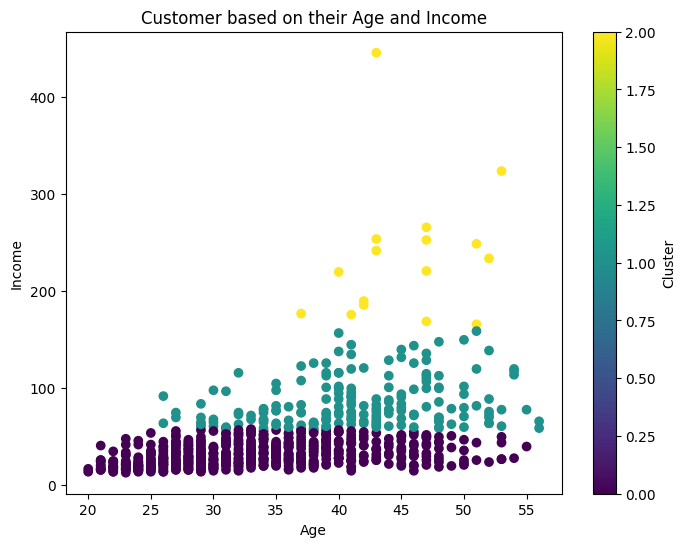

In [136]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df['Age'],
    df['Income'],
    c=df['Cluster'],    
    cmap='viridis',
)

plt.xlabel('Age')
plt.ylabel('Income')
plt.title('Customer based on their Age and Income')
plt.colorbar(label='Cluster')

plt.show()



## **Section 4:Dimensionality Reduction with PCA and t-SNE**

Dimensionality reduction is a key technique for transforming high-dimensional data into a lower-dimensional representation while preserving as much structure as possible.  
In this section, you will apply two widely used methods: **Principal Component Analysis (PCA)** and **t-Distributed Stochastic Neighbor Embedding (t-SNE)**.

### **Objectives**

- Vectorize and standardize the input data  
- Apply **PCA** to extract the most informative linear components  
- Use **t-SNE** to capture nonlinear structure for visualization  
- Compare how each method represents the data  
- Understand when to choose PCA vs. t-SNE based on analytical goals  

### **Key Concepts**

- **Vectorization**: transforming data into numerical vectors suitable for computation  
- **Standardization**: scaling features to zero mean and unit variance before applying PCA or t-SNE  
- **PCA**: a linear method that identifies orthogonal directions of maximum variance  
- **t-SNE**: a nonlinear technique designed for visualizing complex, high-dimensional structure in 2D or 3D  

You will implement both methods, analyze their outputs, and interpret the low-dimensional embeddings.


In [165]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
df=pd.read_excel("Movies_input.xlsx") #input is read.
df.head()

,Movie Names,Movie Description
0,Kshanam,"""Kshanam"" is a gripping Telugu thriller that t..."
1,Evaru,"Directed by Venkat Ramji, ""Evaru"" is a Telugu ..."
2,Goodachari,"""Goodachari"" is a Telugu spy thriller directed..."
3,Awe,"""Awe!"" is a unique Telugu thriller that blends..."
4,Anukshanam,"Directed by Ram Gopal Varma, ""Anukshanam"" is a..."


1. (PCA Implementation)

In [174]:
descriptions = df.iloc[:, 1].values

vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=500 
)

feature_text = vectorizer.fit_transform(descriptions)
X = feature_text.toarray()

scaler = StandardScaler()
feature_std = scaler.fit_transform(X)

pca = PCA(n_components=2)
feature_pca = pca.fit_transform(feature_std)


2. Exploring various attributes and methods of traditional PCA.

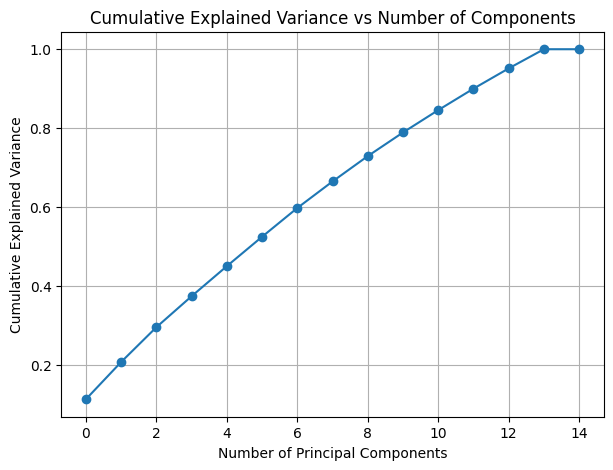

Top contributing words in PC1: ['secrets' 'benefits' 'suspense' 'strong' 'adivi' 'cinematography' 'sesh'
 'values' 'production' 'thriller']


In [150]:
pca_full = PCA()
pca_full.fit(feature_std)

explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

plt.figure(figsize=(7,5))
plt.plot(cumulative_var, marker='o')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance vs Number of Components")
plt.grid(True)
plt.show()

components = pca_full.components_
feature_names = vectorizer.get_feature_names_out()

pc1 = components[0]
top_indices = np.argsort(np.abs(pc1))[-10:]

top_words_pc1 = feature_names[top_indices]
print("Top contributing words in PC1:", top_words_pc1)


3. Calculating explained variance ratio


In [151]:
explained_variance_ratio = pca.explained_variance_ratio_
print("Explained variance ratio for each component is :")
print(explained_variance_ratio)


Explained variance ratio for each component is :
[0.11237166 0.09443819]


4. Projection and reconstruction on correlation matrix

In [164]:
R = np.corrcoef(feature_std, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(R)

idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

k = 9
W = eigenvectors[:, :k]

X_projected = feature_std @ W
X_reconstructed = X_projected @ W.T

reconstruction_error = np.mean((feature_std - X_reconstructed) ** 2)
print("Reconstruction Error:", reconstruction_error)


Reconstruction Error: 0.2710817135221917


5. Generating a lineplot for MSE of reconstruction and original features.

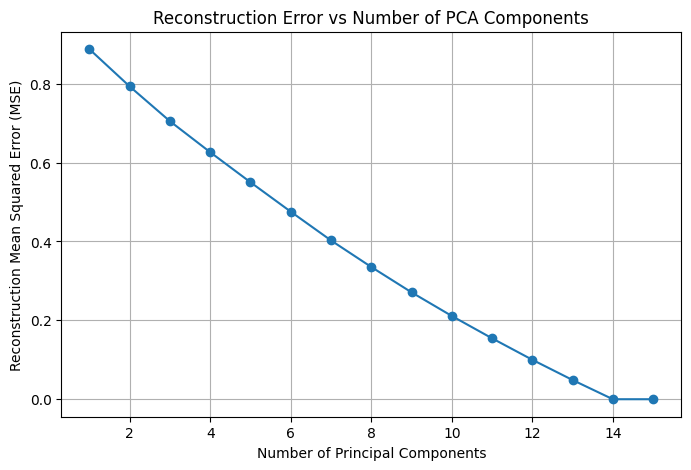

In [157]:
def reconstruction_mse(X_original, X_reconstructed):
    return np.mean((X_original - X_reconstructed) ** 2)

max_components = 15 
mse_values = []
components_range = range(1, max_components + 1)

for k in components_range:
    pca = PCA(n_components=k)
    X_reduced = pca.fit_transform(feature_std)
    X_reconstructed = pca.inverse_transform(X_reduced)
    mse = reconstruction_mse(feature_std, X_reconstructed)
    mse_values.append(mse)


plt.figure(figsize=(8,5))
plt.plot(components_range, mse_values, marker='o')
plt.xlabel("Number of Principal Components")
plt.ylabel("Reconstruction Mean Squared Error (MSE)")
plt.title("Reconstruction Error vs Number of PCA Components")
plt.grid(True)
plt.show()


 **Question:** Reason for the validity of your choice of k with this line plot.

Although the reconstruction MSE becomes zero when k equals 14, this corresponds to retaining all original features and therefore does not achieve dimensionality reduction. The optimal value of k is selected at the elbow point of the MSE curve, where further increases in k yield only marginal improvements in reconstruction error. This choice balances information preservation with dimensionality reduction, making it a valid and effective selection.

6. (PCA vs TSNE)
Analyzing the difference in 2 plots

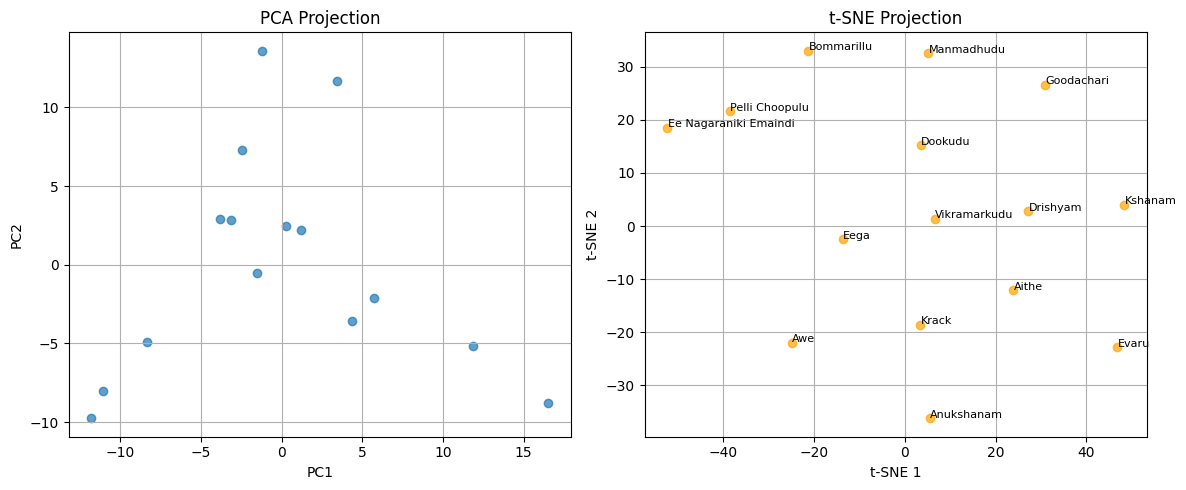

In [181]:
tsne = TSNE(n_components=2, perplexity=5, random_state=42)
X_tsne = tsne.fit_transform(feature_std)


plt.figure(figsize=(12,5))

# PCA plot
plt.subplot(1,2,1)
plt.scatter(feature_pca[:,0], feature_pca[:,1], alpha=0.7)
plt.title("PCA Projection")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)


# t-SNE plot
plt.subplot(1,2,2)
plt.scatter(X_tsne[:,0], X_tsne[:,1], alpha=0.7, color='orange')
plt.title("t-SNE Projection")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True)
for i, name in enumerate(df.iloc[:,0]):
    plt.text(X_tsne[i,0]+0.1, X_tsne[i,1]+0.1, name, fontsize=8)


plt.tight_layout()
plt.show()


## **Section 5 : Using Grid Search to Improve Machine Learning Models**

In this section, you will explore how **Grid Search** can be used to optimize hyperparameters and improve model performance. You will begin by fitting a baseline **Decision Tree** classifier to a sample dataset. This initial model is expected to **overfit**, providing an opportunity to observe how hyperparameter tuning can mitigate such behavior.

### **Workflow Overview**

1. Fit an initial Decision Tree model  
2. Evaluate its performance and observe evidence of overfitting  
3. Define a hyperparameter grid (e.g., max depth, min samples split, criterion)  
4. Apply **Grid Search** to systematically explore combinations  
5. Identify the parameter set that minimizes overfitting and improves generalization  
6. Refit and evaluate the optimized model  

Grid Search provides a structured, exhaustive method for evaluating a model's performance across different hyperparameter settings, ensuring that the selected configuration is supported by empirical validation.

### **Next Step**

Begin by importing the required packages and utilities for model training, evaluation, and grid search.


In [193]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import f1_score, make_scorer
from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

1. Reading and plotting the data
Now, a function that will help us read the csv file, and plot the data.

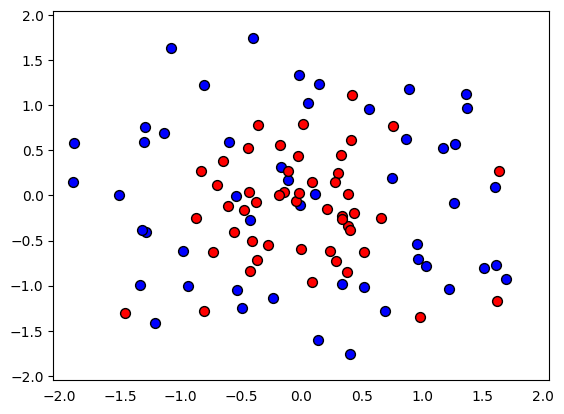

In [183]:
def load_pts(csv_name):
    data = np.asarray(pd.read_csv(csv_name, header=None))
    X = data[:,0:2]
    y = data[:,2]

    plt.scatter(X[np.argwhere(y==0).flatten(),0], X[np.argwhere(y==0).flatten(),1],s = 50, color = 'blue', edgecolor = 'k')
    plt.scatter(X[np.argwhere(y==1).flatten(),0], X[np.argwhere(y==1).flatten(),1],s = 50, color = 'red', edgecolor = 'k')
    
    plt.xlim(-2.05,2.05)
    plt.ylim(-2.05,2.05)
    plt.grid(False)
    plt.tick_params(
        axis='x',
        which='both',
        bottom=False,
        top=False)

    return X,y

X, y = load_pts('data.csv')
plt.show()

2. Splitting our data into training and testing sets

In [185]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

3. Fitting a Decision Tree model

In [189]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred = dt_model.predict(X_test)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Detailed report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Confusion matrix
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 0.7

Classification Report:
               precision    recall  f1-score   support

         0.0       0.58      0.88      0.70         8
         1.0       0.88      0.58      0.70        12

    accuracy                           0.70        20
   macro avg       0.73      0.73      0.70        20
weighted avg       0.76      0.70      0.70        20


Confusion Matrix:
 [[7 1]
 [5 7]]


4. Using grid search to improve this model.

### **Grid Search Procedure**

In this part of the project, you will implement a full hyperparameter tuning pipeline for the Decision Tree classifier. The workflow consists of the following steps:

1. **Define the Hyperparameter Search Space**  
   Select a set of Decision Tree parameters to explore. Common choices include:  
   - `max_depth`  
   - `min_samples_leaf`  
   - `min_samples_split`  
   You may adjust the ranges as needed based on model performance.

2. **Create a Scoring Function**  
   Use `f1_score` as the evaluation metric by wrapping it with `make_scorer`.  
   F1 is particularly useful when classes are imbalanced or when precision and recall must be balanced.

3. **Run Grid Search**  
   Apply `GridSearchCV` using:  
   - The classifier  
   - The defined hyperparameter grid  
   - The F1 scorer  
   - Cross-validation for robust evaluation

4. **Fit the Optimized Model**  
   Train the model using the best hyperparameter configuration returned by the grid search.

5. **Evaluate and Visualize Results**  
   - Plot the resulting Decision Tree  
   - Compute and report the final F1 score  
   - Assess whether the optimized model reduces overfitting compared to the initial baseline

6. **Iterate if Necessary**  
   If the model’s performance does not improve significantly, revisit and expand the hyperparameter ranges.  
   Continue refining until the validation results demonstrate meaningful improvements.

This process illustrates how systematic hyperparameter tuning can help control overfitting and enhance generalization performance in machine learning models.


In [207]:
param_grid = {
    'max_depth': [None, 4, 6, 7, 10, 18],           
    'min_samples_split': [8, 7, 10,15, 20, 30],
    'min_samples_leaf': [1, 2, 4]
}

f1_scorer = make_scorer(f1_score, average='weighted') 

grid_search = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid,
    scoring=f1_scorer,
    cv=5,                 
    n_jobs=-1,           
    verbose=1
)


grid_search.fit(X_train, y_train)
print("Best Hyperparameters are :", grid_search.best_params_)
print("Best F1 Score is :", grid_search.best_score_)

best_dt = grid_search.best_estimator_
y_pred = best_dt.predict(X_test)

# F1 score on test set
f1_test = f1_score(y_test, y_pred, average='weighted')
print("F1 Score on Test Data is :", f1_test)
print(classification_report(y_test, y_pred))




Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Hyperparameters are : {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 20}
Best F1 Score is : 0.7862605042016806
F1 Score on Test Data is : 0.8
              precision    recall  f1-score   support

         0.0       0.67      1.00      0.80         8
         1.0       1.00      0.67      0.80        12

    accuracy                           0.80        20
   macro avg       0.83      0.83      0.80        20
weighted avg       0.87      0.80      0.80        20



## **Sextion 6 : H2O AutoML Example with Multivariate Time Series**

This section demonstrates how to use **H2O AutoML** to forecast a target signal in a multivariate time-series setting.  
The workflow is designed to run within **Google Colaboratory**, making it easy to leverage H2O’s distributed machine-learning engine directly in a cloud environment.

### **Overview**

- The feature matrix is constructed from **lagged values** of the target series as well as lagged values of additional explanatory features.  
- H2O AutoML is then used to automatically train, tune, and select high-performing models for forecasting.  
- Unlike recurrent architectures such as **LSTM**, the models generated by AutoML are **memoryless**—they do not inherently capture temporal dependencies.  
  Instead, all temporal structure must be explicitly encoded into the feature matrix through lagged variables.

### **What You Will Do in This Section**

- Initialize and configure the H2O runtime in Colab  
- Build a supervised learning dataset using lag features  
- Run H2O AutoML on the multivariate time-series data  
- Evaluate forecasting performance and examine the leaderboard  
- Highlight the contrast between feature-engineered models and sequence models such as LSTM

This section illustrates how classical machine-learning models—when combined with appropriate feature engineering—can still perform competitively in forecasting tasks without relying on deep learning architectures.


1. Install Java
necessary for H2O
version 8
note the exclamation '!' is a cell magic that allows us to execute commands (in this case Ubuntu linux)


In [ ]:
!apt-get install openjdk-8-jdk -qq > /dev/null

The system cannot find the path specified.


2. install h2o library

In [211]:
%pip install h2o -qq

Note: you may need to restart the kernel to use updated packages.


3. Import Dependencies

In [ ]:
import pandas as pd
import h2o
from h2o.automl import H2OAutoML

import matplotlib.pyplot as plt
from scipy import stats

4. Read pollution.csv into pandas df
set date as index
display first 5 rows
the Air Pollution data is discussed here: https://machinelearningmastery.com/multivariate-time-series-forecasting-lstms-keras/
this is a dataset that reports on the weather and the level of pollution each hour for five years at the US embassy in Beijing, China.
we can use this data and frame a forecasting problem where, given the weather conditions and pollution for prior hours, we forecast the pollution at the next hour.

In [4]:
df=pd.read_csv("pollution.csv") #input is read.
df.head()
     

,date,pollution,dew,temp,press,wnd_dir,wnd_spd,snow,rain
0,2010-01-02 00:00:00,129.0,-16,-4.0,1020.0,SE,1.79,0,0
1,2010-01-02 01:00:00,148.0,-15,-4.0,1020.0,SE,2.68,0,0
2,2010-01-02 02:00:00,159.0,-11,-5.0,1021.0,SE,3.57,0,0
3,2010-01-02 03:00:00,181.0,-7,-5.0,1022.0,SE,5.36,1,0
4,2010-01-02 04:00:00,138.0,-7,-5.0,1022.0,SE,6.25,2,0


5. Plot the data

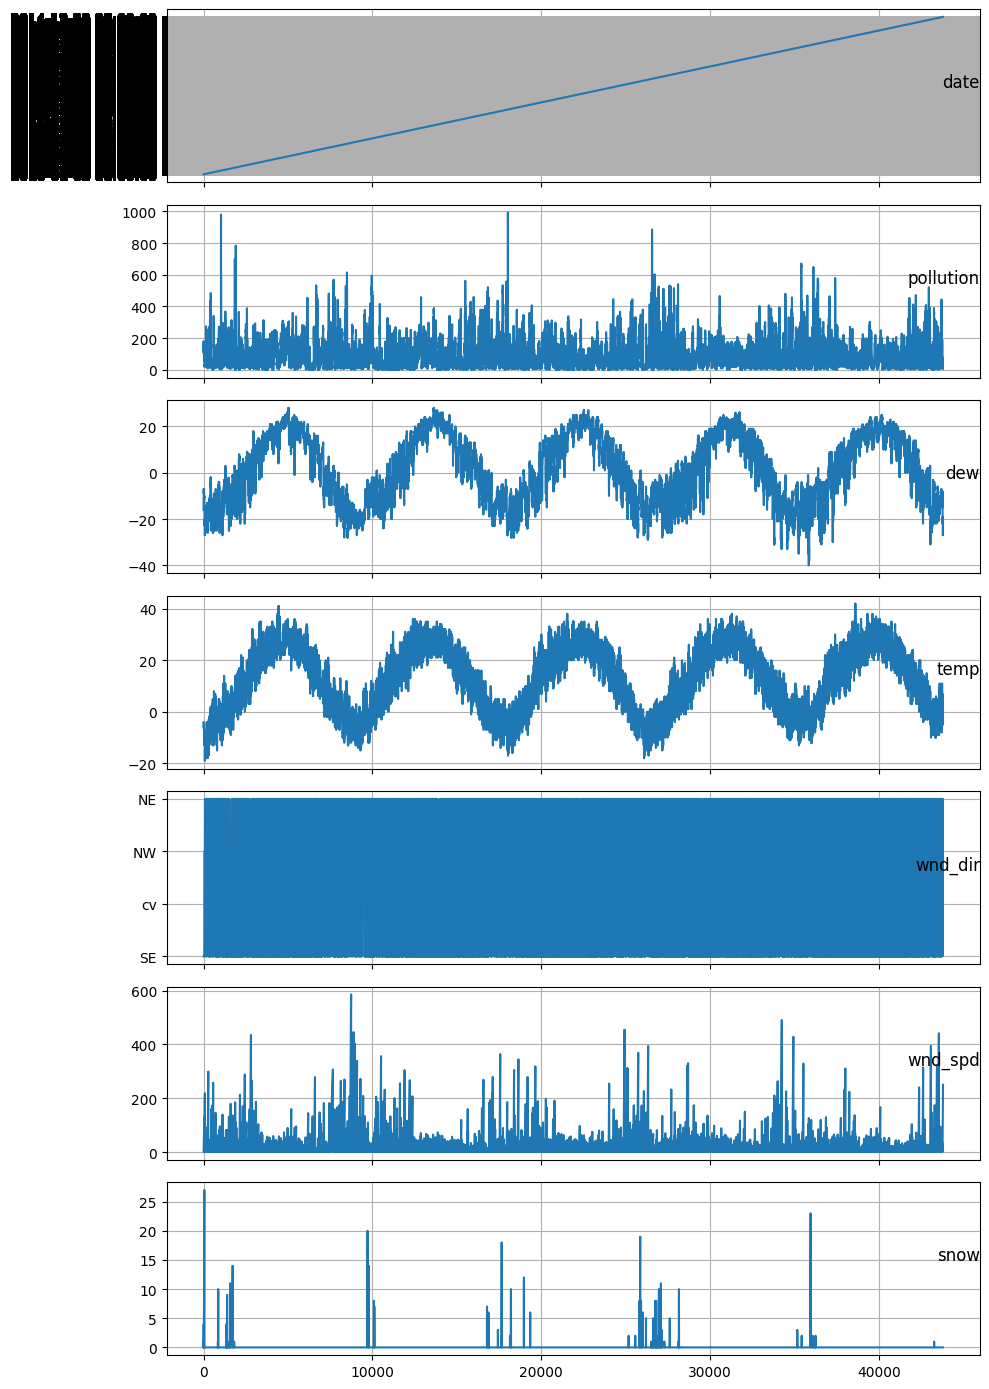

In [6]:
X = df.values
groups = [0, 1, 2, 3, 5, 6, 7]

fig, axes = plt.subplots(len(groups), 1, figsize=(10, 2*len(groups)), sharex=True)

for idx, group in enumerate(groups):
    axes[idx].plot(X[:, group])
    axes[idx].set_title(df.columns[group], loc='right', y=0.5)
    axes[idx].grid(True)

plt.tight_layout()
plt.show()


6. Inorder to model the time-series with conventional supervised machine learning, the data must be preprocessed
in this case, we will just predict the target signal ('pollution') one step ahead
the features and the target will be lagged by num_lags and aggregated by mean with windows of num_lags

In [19]:
df_lagged = df.copy()

n = 3      
delay = 1       
for col in df_lagged.columns:
    for l in range(1, n + 1):

        shift_steps = -l - (delay - 1)
        df_lagged[f'{col}_lag{l}'] = df_lagged[col].shift(shift_steps)

        if col != 'wnd_dir' and col != 'date':
            base_shift = -1 - (delay - 1)
            window_size = l + 1

            rolling_mean = (
                df_lagged[col]
                .shift(base_shift)
                .rolling(window=window_size)
                .mean()
                .shift(1 - window_size)
            )

            df_lagged[f'{col}_avg_window_length{window_size}'] = rolling_mean


df_lagged.dropna(inplace=True)

selected_cols = df_lagged.columns[
    df_lagged.columns.str.contains('pollution') |
    df_lagged.columns.str.contains('lag') |
    df_lagged.columns.str.contains('window')
]

df_final = df_lagged[selected_cols]
df_final.columns


Index(['pollution', 'date_lag1', 'date_lag2', 'date_lag3', 'pollution_lag1',
       'pollution_avg_window_length2', 'pollution_lag2',
       'pollution_avg_window_length3', 'pollution_lag3',
       'pollution_avg_window_length4', 'dew_lag1', 'dew_avg_window_length2',
       'dew_lag2', 'dew_avg_window_length3', 'dew_lag3',
       'dew_avg_window_length4', 'temp_lag1', 'temp_avg_window_length2',
       'temp_lag2', 'temp_avg_window_length3', 'temp_lag3',
       'temp_avg_window_length4', 'press_lag1', 'press_avg_window_length2',
       'press_lag2', 'press_avg_window_length3', 'press_lag3',
       'press_avg_window_length4', 'wnd_dir_lag1', 'wnd_dir_lag2',
       'wnd_dir_lag3', 'wnd_spd_lag1', 'wnd_spd_avg_window_length2',
       'wnd_spd_lag2', 'wnd_spd_avg_window_length3', 'wnd_spd_lag3',
       'wnd_spd_avg_window_length4', 'snow_lag1', 'snow_avg_window_length2',
       'snow_lag2', 'snow_avg_window_length3', 'snow_lag3',
       'snow_avg_window_length4', 'rain_lag1', 'rain_avg_wind

7. Take a look at the pollution lags and windows

In [20]:
filter = df_final.columns.str.contains('pollution')
df_final[df_final.columns[filter]].head(7)

,pollution,pollution_lag1,pollution_avg_window_length2,pollution_lag2,pollution_avg_window_length3,pollution_lag3,pollution_avg_window_length4
0,129.0,148.0,153.5,159.0,162.666667,181.0,156.50
1,148.0,159.0,170.0,181.0,159.333333,138.0,146.75
2,159.0,181.0,159.5,138.0,142.666667,109.0,133.25
3,181.0,138.0,123.5,109.0,117.333333,105.0,119.00
4,138.0,109.0,107.0,105.0,112.666667,124.0,114.50
5,109.0,105.0,114.5,124.0,116.333333,120.0,120.25
6,105.0,124.0,122.0,120.0,125.333333,132.0,129.00


8. perform train/test split
split the data sequentially mainting chronological order
80% train/ 20% test

In [21]:
df_final.reset_index(drop=True,inplace=True)
train = df_final.loc[:int(df_final.shape[0]*0.8),:]
test = df_final.loc[int(df_final.shape[0]*0.8):,:]

9. plot the train/test split

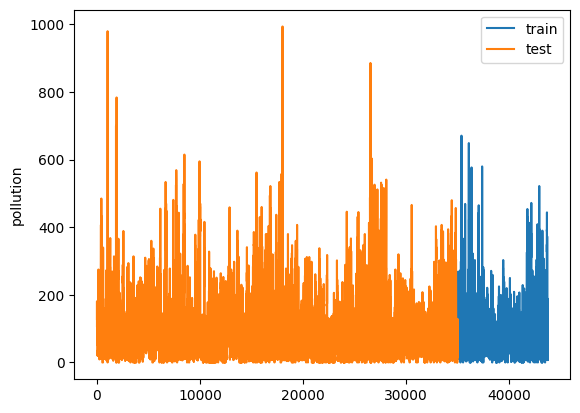

In [23]:
#Plot

plt.plot(test.index,test['pollution'])
plt.plot(train.index,train['pollution'])

plt.ylabel('pollution')
plt.legend(['train','test'])
plt.show()

10. Initialize h2o session

In [24]:

h2o.init(nthreads=-1)

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
; OpenJDK 64-Bit Server VM Temurin-21.0.4+7 (build 21.0.4+7-LTS, mixed mode, sharing)
  Starting server from <local-user-path>\AppData\Local\Programs\Python\Python311\Lib\site-packages\h2o\backend\bin\h2o.jar
  Ice root: <local-user-path>\AppData\Local\Temp\tmpxbd1zfsc
  JVM stdout: <local-user-path>\AppData\Local\Temp\tmpxbd1zfsc\h2o_Saba_started_from_python.out
  JVM stderr: <local-user-path>\AppData\Local\Temp\tmpxbd1zfsc\h2o_Saba_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,11 secs
H2O_cluster_timezone:,Asia/Tehran
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.9
H2O_cluster_version_age:,22 days
H2O_cluster_name:,H2O_from_python_Saba_q184vx
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,2.954 Gb
H2O_cluster_total_cores:,0
H2O_cluster_allowed_cores:,0
H2O_cluster_status:,"locked, healthy"


11. Convert pandas dataframes to h2o frames

In [27]:
train_h2o = h2o.H2OFrame(train)
test_h2o = h2o.H2OFrame(test)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


12. Select response and features
y: target signal
X: feature matrix with lagged values

In [28]:
y = "pollution"
X = train_h2o.columns
X.remove(y)

13. Run AutoML

In [30]:
aml = H2OAutoML(max_models=10, seed=1, max_runtime_secs=600)
aml.train(x=X, y=y, training_frame=train_h2o , leaderboard_frame = test_h2o)

AutoML progress: |
00:22:55.650: AutoML: XGBoost is not available; skipping it.

███████████████████████████████████████████████████████████████| (done) 100%


key,value
Stacking strategy,cross_validation
Number of base models (used / total),5/5
# GBM base models (used / total),1/1
# DeepLearning base models (used / total),1/1
# DRF base models (used / total),2/2
# GLM base models (used / total),1/1
Metalearner algorithm,GLM
Metalearner fold assignment scheme,Random
Metalearner nfolds,5
Metalearner fold_column,None


14. Check the leaderboard
models are ranked by peformance on the test data since we specified a leadboard_frame

In [34]:
leaderboard = aml.leaderboard
print(leaderboard)


model_id                                                   rmse      mse      mae       rmsle    mean_residual_deviance
StackedEnsemble_BestOfFamily_1_AutoML_2_20251217_02255  23.3628  545.82   12.5423    0.457782                   545.82
GBM_1_AutoML_2_20251217_02255                           23.4856  551.572  12.7161    0.450752                   551.572
StackedEnsemble_AllModels_1_AutoML_2_20251217_02255     23.7125  562.283  12.8725    0.467957                   562.283
DeepLearning_1_AutoML_2_20251217_02255                  23.8222  567.498  13.6076  nan                          567.498
GBM_3_AutoML_2_20251217_02255                           24.0341  577.64   12.6492    0.451913                   577.64
GBM_2_AutoML_2_20251217_02255                           24.1254  582.036  12.6094    0.450041                   582.036
DRF_1_AutoML_2_20251217_02255                           24.2056  585.911  12.9846    0.462282                   585.911
GLM_1_AutoML_2_20251217_02255             


15. Select the top model

In [35]:
top_model = aml.leader
print(top_model)

Model Details
H2OStackedEnsembleEstimator : Stacked Ensemble
Model Key: StackedEnsemble_BestOfFamily_1_AutoML_2_20251217_02255


Model Summary for Stacked Ensemble: 
key                                        value
-----------------------------------------  ----------------
Stacking strategy                          cross_validation
Number of base models (used / total)       5/5
# GBM base models (used / total)           1/1
# DeepLearning base models (used / total)  1/1
# DRF base models (used / total)           2/2
# GLM base models (used / total)           1/1
Metalearner algorithm                      GLM
Metalearner fold assignment scheme         Random
Metalearner nfolds                         5
Metalearner fold_column
Custom metalearner hyperparameters         None

ModelMetricsRegressionGLM: stackedensemble
** Reported on train data. **

MSE: 304.65667197133956
RMSE: 17.454416975978877
MAE: 9.47496010102485
RMSLE: 0.5061363221061398
Mean Residual Deviance: 304.65667197133956
R

16. Make predictions on the test data

In [37]:
prediction = top_model.predict(test_h2o)
prediction.head(10)

df_prediction = pd.DataFrame()
df_prediction['ground_truth'] = test['pollution'].reset_index(drop=True)
df_prediction['predictions'] = h2o.as_list(prediction,use_pandas=True)
df_prediction.head()

stackedensemble prediction progress: |

███████████████████████████████████████████| (done) 100%


<local-user-path>\AppData\Local\Programs\Python\Python311\Lib\site-packages\h2o\frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,ground_truth,predictions
0,18.0,19.629389
1,23.0,18.980265
2,20.0,23.092205
3,23.0,25.777389
4,24.0,52.102946


17. Get R2 for this prediction

In [38]:
perf = top_model.model_performance(test_h2o)
r2 = perf.r2()
print("R2: ", r2)


R2:  0.9376504592037207


18. Let's now try to predict 5 steps ahead
this time, we'll put everything into one notebook cell

In [40]:
df_lagged = df.copy()

n = 5      
delay = 5       
for col in df_lagged.columns:
    for l in range(1, n + 1):

        shift_steps = -l - (delay - 1)
        df_lagged[f'{col}_lag{l}'] = df_lagged[col].shift(shift_steps)

        if col != 'wnd_dir' and col != 'date':
            base_shift = -1 - (delay - 1)
            window_size = l + 1

            rolling_mean = (
                df_lagged[col]
                .shift(base_shift)
                .rolling(window=window_size)
                .mean()
                .shift(1 - window_size)
            )

            df_lagged[f'{col}_avg_window_length{window_size}'] = rolling_mean


df_lagged.dropna(inplace=True)

selected_cols = df_lagged.columns[
    df_lagged.columns.str.contains('pollution') |
    df_lagged.columns.str.contains('lag') |
    df_lagged.columns.str.contains('window')
]

df_final = df_lagged[selected_cols]
df_final.columns


df_final.reset_index(drop=True,inplace=True)
train = df_final.loc[:int(df_final.shape[0]*0.8),:]
test = df_final.loc[int(df_final.shape[0]*0.8):,:]

train_h2o = h2o.H2OFrame(train)
test_h2o = h2o.H2OFrame(test)

y = "pollution"
X = train_h2o.columns
X.remove(y)

aml = H2OAutoML(max_models=10, seed=1, max_runtime_secs=600)
aml.train(x=X, y=y, training_frame=train_h2o , leaderboard_frame = test_h2o)

top_model = aml.leader
print(top_model)

prediction = top_model.predict(test_h2o)
prediction.head(10)

df_prediction = pd.DataFrame()
df_prediction['ground_truth'] = test['pollution'].reset_index(drop=True)
df_prediction['predictions'] = h2o.as_list(prediction,use_pandas=True)
df_prediction.head()

perf = top_model.model_performance(test_h2o)
r2 = perf.r2()
print("R2: ", r2)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
AutoML progress: |
00:48:46.125: AutoML: XGBoost is not available; skipping it.

███████████████████████████████████████████████████████████████| (done) 100%
Model Details
H2OGeneralizedLinearEstimator : Generalized Linear Modeling
Model Key: GLM_1_AutoML_3_20251217_04846


GLM Model: summary
    family    link      regularization               lambda_search                                                                   number_of_predictors_total    number_of_active_predictors    number_of_iterations    training_frame
--  --------  --------  ---------------------------  ------------------------------------------------------------------------------  ----------------------------  -----------------------------  ----------------------  -----------------------------------------------------------------

<local-user-path>\AppData\Local\Programs\Python\Python311\Lib\site-packages\h2o\frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


R2:  0.6695673969910079


**Question:** Things to Try:

* Compare with univarate model
* Compare with LSTM

## **Section 7 : Multilayer Perceptron (MLP) Example**

In this section, you will build and evaluate a **Multilayer Perceptron (MLP)**, one of the fundamental neural network architectures used for supervised learning tasks.  
An MLP consists of fully connected layers that learn hierarchical representations of the input data through nonlinear transformations.

### **Overview**

- An MLP is composed of an input layer, one or more **hidden layers** with nonlinear activation functions, and an output layer.  
- Unlike convolutional or recurrent architectures, an MLP does not incorporate spatial or temporal biases—it treats all input features uniformly.  
- Despite its simplicity, an MLP can model complex decision boundaries when trained properly.

### **What You Will Do in This Section**

- Prepare and preprocess the dataset for neural network training  
- Construct a Multilayer Perceptron using a deep learning framework (e.g., PyTorch, TensorFlow, Keras, or scikit-learn)  
- Choose activation functions, hidden layer sizes, and regularization strategies  
- Train the model and analyze its learning curves  
- Evaluate performance using appropriate metrics  
- Experiment with architectural and hyperparameter changes to improve accuracy

This section will help you understand how fully connected neural networks operate and how to configure them effectively for practical machine-learning tasks.


In [33]:
import numpy as np
import pickle, gzip
import matplotlib.pyplot as plt
import os
import urllib.request
import pandas as pd
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import seaborn as sns


1. Loading dataset
The dataset utilzied for this example can be downloaded from http://deeplearning.net/data/mnist/mnist.pkl.gz and consist of a subset (20k examples) of the famous MNIST dataset. plot random from it samples

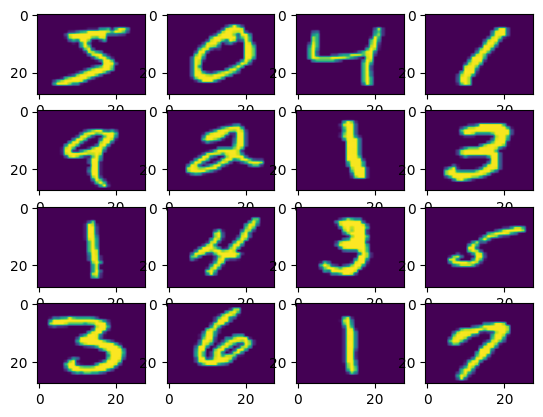

In [17]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

fig, im = plt.subplots(4, 4)
k = 0
for i in range(4):
    for j in range(4):
        im[i][j].imshow(x_train[k].reshape(28, 28), aspect='auto')
        k += 1
plt.show()

For sake of time, the MLP is trained with the validation set (10K examples); testing is performed with the test set (10K examples)

In [18]:
print("shape of x_train:", x_train.shape)
print("shape of y_train:", y_train.shape)
print("shape of x_test:", x_test.shape)
print("shape of y_test:", y_test.shape)

shape of x_train: (60000, 28, 28)
shape of y_train: (60000,)
shape of x_test: (10000, 28, 28)
shape of y_test: (10000,)


2. Parameters of MLP
Number of layers : 4 (input, hidden1, hidden2 output)
Elements in layers : [784, 25, 10, 10]
Activation function : Rectified Linear function
Regularization parameter : 1

In [28]:
mlp = MLPClassifier(
    hidden_layer_sizes=(25, 10),
    activation='relu',
    alpha=1,              
    solver='adam',
    max_iter=70,
    random_state=42
)
x_train = x_train.reshape(x_train.shape[0], -1)
x_test  = x_test.reshape(x_test.shape[0], -1)

3. Creating MLP object

In [ ]:
# It has been made in section 2 (mlp)

4. Training MLP object

In [29]:
mlp.fit(x_train, y_train)

<local-user-path>\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (70) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(alpha=1, hidden_layer_sizes=(25, 10), max_iter=70,
              random_state=42)

5. Testing MLP

In [31]:
y_test_pred = mlp.predict(x_test)

acc = accuracy_score(y_test, y_test_pred)
print("Test Accuracy:", acc)

Test Accuracy: 0.9621


6. Plotting some weights
A. Weights from Input layer to Hidden layer 1

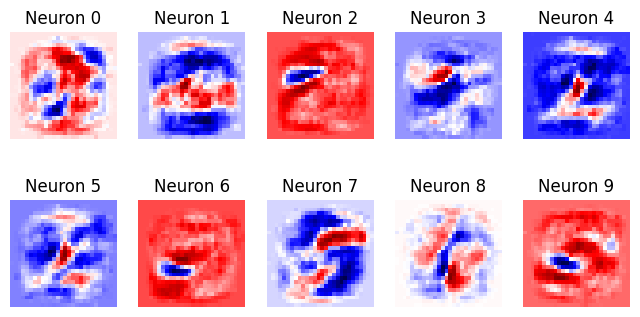

In [32]:
W_A = mlp.coefs_[0]

plt.figure(figsize=(8,4))
for i in range(10): 
    plt.subplot(2,5,i+1)
    plt.imshow(W_A[:, i].reshape(28,28), cmap='seismic')
    plt.axis('off')
    plt.title(f'Neuron {i}')
plt.show()


B. Weights from Hidden layer 1 to Hidden layer 2

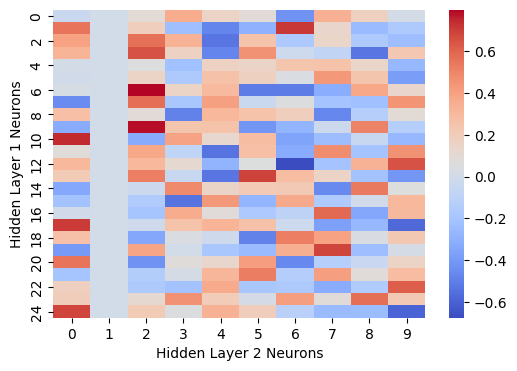

In [34]:
W_B = mlp.coefs_[1]   

plt.figure(figsize=(6,4))
sns.heatmap(W_B, cmap='coolwarm')
plt.xlabel("Hidden Layer 2 Neurons")
plt.ylabel("Hidden Layer 1 Neurons")
plt.show()


C. Weights from Hidden layer 2 to Output layer

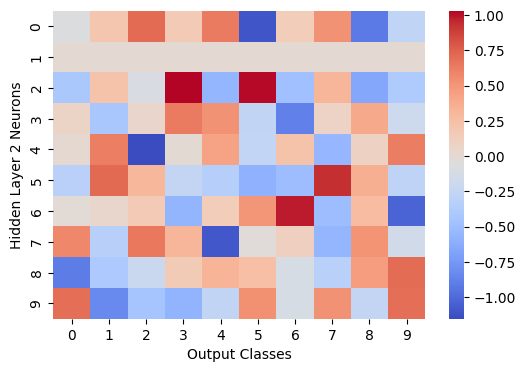

In [35]:
W_C = mlp.coefs_[2]

plt.figure(figsize=(6,4))
sns.heatmap(W_C, cmap='coolwarm')
plt.xlabel("Output Classes")
plt.ylabel("Hidden Layer 2 Neurons")
plt.show()


## **Section 8 : Long Short-Term Memory (LSTM) Networks**

In this section, you will work with **Long Short-Term Memory (LSTM)** networks, a specialized type of recurrent neural network designed to model sequential data.  
LSTMs address the limitations of standard RNNs by incorporating gating mechanisms that enable them to retain and forget information over long sequences.

### **Overview**

- LSTMs are well-suited for tasks involving **time-series forecasting**, **natural language processing**, and any problem where temporal dependencies are important.  
- They maintain an internal memory state through **input**, **forget**, and **output** gates, allowing them to capture long-range patterns that conventional RNNs struggle with.  
- Unlike classical ML models or MLPs, LSTMs inherently model sequence dynamics without requiring manual lag-feature engineering.

### **What You Will Do in This Section**

- Prepare sequential data for LSTM input, including shaping into `(samples, timesteps, features)`  
- Build an LSTM model using a deep learning framework (e.g., TensorFlow/Keras, PyTorch)  
- Configure key hyperparameters such as hidden size, number of layers, dropout, and sequence length  
- Train the LSTM model and visualize loss and accuracy trends  
- Evaluate performance and compare it to simpler models (e.g., MLP, linear models, AutoML lag-based models)  
- Discuss when LSTMs outperform classical approaches and when they do not

This section will deepen your understanding of sequential modeling and show how LSTMs can capture complex temporal relationships in data.


In [36]:
import numpy
import matplotlib.pyplot as plt
import pandas
import math
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

In [37]:

# load the dataset
dataframe = pandas.read_csv('airline-passengers.csv', usecols=[1], engine='python')
dataset = dataframe.values
dataset = dataset.astype('float32')

1. Normalize the dataset

In [38]:
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

2. Split into train and test sets

In [39]:
train_len = int(len(dataset) * 0.8)
test_len = int(len(dataset) * 0.2)
x_train, x_test = dataset[0:train_len,:], dataset[train_len:len(dataset),:]

3. Convert an array of values into a dataset matrix

In [40]:
def matrix(dataset, lb=1):

    X, Y = [], []
    
    for i in range(len(dataset)-lb-1):

        j = dataset[i:(i+lb), 0]
        X.append(j)
        Y.append(dataset[i + lb, 0])

    return np.array(X), np.array(Y)

4. Reshape into X=t and Y=t+1

In [41]:
x_train, y_train = matrix(x_train, 3)
x_test, y_test = matrix(x_test, 3)

5. Reshape input to be [samples, time steps, features]

In [42]:
x_train = np.reshape(x_train, (x_train.shape[0], 1, x_train.shape[1]))
x_test = np.reshape(x_test, (x_test.shape[0], 1, x_test.shape[1]))

6. Create and fit the LSTM network

In [43]:
LSTM_model = Sequential()
LSTM_model.add(LSTM(4, input_shape=(1, 3)))
LSTM_model.add(Dense(1))
LSTM_model.compile(loss='mean_squared_error', optimizer='adam')
LSTM_model.fit(x_train, y_train, epochs=100, batch_size=1, verbose=2)



Epoch 1/100

111/111 - 5s - loss: 0.0765 - 5s/epoch - 44ms/step
Epoch 2/100
111/111 - 0s - loss: 0.0319 - 205ms/epoch - 2ms/step
Epoch 3/100
111/111 - 0s - loss: 0.0201 - 194ms/epoch - 2ms/step
Epoch 4/100
111/111 - 0s - loss: 0.0166 - 191ms/epoch - 2ms/step
Epoch 5/100
111/111 - 0s - loss: 0.0139 - 184ms/epoch - 2ms/step
Epoch 6/100
111/111 - 0s - loss: 0.0117 - 187ms/epoch - 2ms/step
Epoch 7/100
111/111 - 0s - loss: 0.0099 - 186ms/epoch - 2ms/step
Epoch 8/100
111/111 - 0s - loss: 0.0085 - 185ms/epoch - 2ms/step
Epoch 9/100
111/111 - 0s - loss: 0.0074 - 184ms/epoch - 2ms/step
Epoch 10/100
111/111 - 0s - loss: 0.0065 - 205ms/epoch - 2ms/step
Epoch 11/100
111/111 - 0s - loss: 0.0061 - 193ms/epoch - 2ms/step
Epoch 12/100
111/111 - 0s - loss: 0.0057 - 192ms/epoch - 2ms/step
Epoch 13/100
111/111 - 0s - loss: 0.0055 - 229ms/epoch - 2ms/step
Epoch 14/100
111/111 - 0s - loss: 0.0055 - 218ms/epoch - 2ms/step
Epoch 15/100
111/111 - 0s - loss: 0.0052 - 211ms/epoch - 2ms/step
Epoch 16/100
111/1

7. 
* Make predictions
* Invert predictions
* Calculate root mean squared error

In [44]:
# Make predictions
trainPrediction_LSTM = LSTM_model.predict(x_train)
testPrediction_LSTM = LSTM_model.predict(x_test)

# Invert predictions
trainPrediction_LSTM = scaler.inverse_transform(trainPrediction_LSTM)
y_train = scaler.inverse_transform([y_train])
testPrediction_LSTM = scaler.inverse_transform(testPrediction_LSTM)
y_test = scaler.inverse_transform([y_test])

# root mean squared error
trainScore = np.sqrt(np.mean(np.square(trainPrediction_LSTM - y_train)))
print('Train Score is : %.2f RMSE' % (trainScore))
testScore = np.sqrt(np.mean(np.square(testPrediction_LSTM - y_test)))
print('Test Score is : %.2f RMSE' % (testScore))

1/1 [==============================] - 0s 51ms/step
Train Score is : 120.55 RMSE
Test Score is : 105.01 RMSE


8. Shift training predictions for plotting

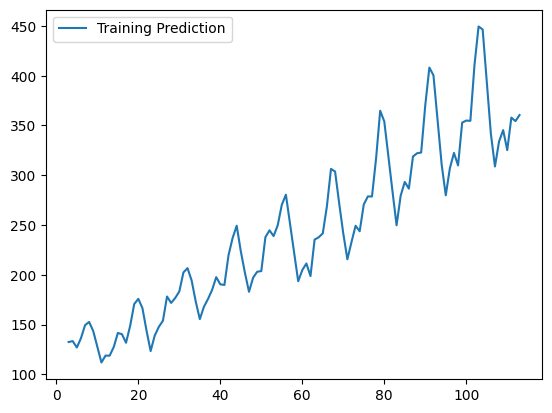

In [45]:
look_back = 3

training_Prediction = np.empty_like(dataset)
training_Prediction[:, :] = np.nan
training_Prediction[look_back:len(trainPrediction_LSTM)+look_back, :] = trainPrediction_LSTM

plt.plot(training_Prediction, label='Training Prediction')
plt.legend()
plt.show()

9. Shift test predictions for plotting

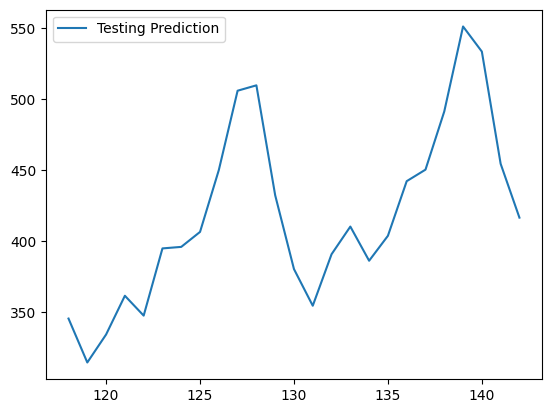

In [54]:
look_back = 3

testing_Prediction = np.empty_like(dataset)
testing_Prediction[:, :] = np.nan
testing_Prediction[len(trainPrediction_LSTM)+(look_back*2)+1:len(dataset)-1, :] = testPrediction_LSTM

plt.plot(testing_Prediction, label='Testing Prediction')
plt.legend()
plt.show()

10. Plot baseline and predictions

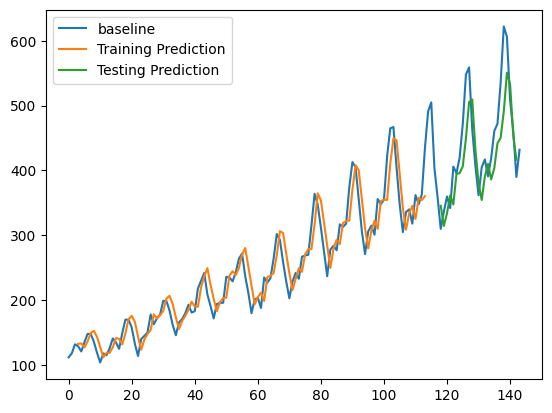

In [55]:
plt.plot(scaler.inverse_transform(dataset), label='baseline')
plt.plot(training_Prediction, label='Training Prediction')
plt.plot(testing_Prediction, label='Testing Prediction')
plt.legend()
plt.show()

## **9. DVC Assignment**

In this section, you will convert a simple machine-learning workflow into a fully reproducible, version-controlled pipeline using **DVC (Data Version Control)** inside a Kaggle Notebook environment. You may choose any small public Kaggle dataset (e.g., Titanic, Iris, Penguins, House Prices), ideally under 50 MB.

### **Overview of the Workflow**

You will build a two-stage DVC pipeline consisting of:

1. **Data Preprocessing Stage**  
2. **Model Training and Evaluation Stage**

DVC will manage your raw data, processed data, models, and metrics, ensuring that every step is reproducible and driven by explicit dependencies.

### **Workflow Steps**

1. **Initialize Project**
   - Set up a Git repository inside the Kaggle Notebook.
   - Install and initialize DVC (`dvc init`).
   - Import or upload the dataset and treat it as your **raw data** input.
   - Add raw data to DVC (`dvc add data/raw/...`) so it is version-controlled.

2. **Create the Preprocessing Stage**
   - Write a small script or notebook cell that cleans the raw dataset.
   - Save a processed version (e.g., `data/processed/data.csv`).
   - Use DVC to define a stage where:
     - Inputs: raw data  
     - Outputs: processed data  
     - Command: your preprocessing script  
   - This becomes the first stage in `dvc.yaml`.

3. **Create the Model Training Stage**
   - Train a simple model: logistic regression, decision tree, or similar.
   - Save the model artifact (e.g., `models/model.pkl`).
   - Save evaluation metrics in JSON format (e.g., `metrics.json`).
   - Add a second DVC stage where:
     - Inputs: processed data  
     - Outputs: model and metrics  
     - Command: your training script  

4. **Run and Test the Pipeline**
   - Execute `dvc repro` to build the entire pipeline.
   - Modify one element (e.g., hyperparameter, preprocessing rule).
   - Run `dvc repro` again and observe that DVC only rebuilds the affected stage(s), not the whole pipeline.

5. **Documentation**
   - Include the generated `dvc.yaml` and `dvc.lock` in the notebook.
   - Provide a short explanation summarizing:
     - What you changed  
     - Which stages DVC re-executed  
     - Why DVC rebuilt only those components  

### **Learning Objectives**

By completing this section, you will demonstrate:

- How DVC tracks data, code, and dependencies  
- How pipelines are defined and reproduced in a notebook environment  
- The difference between modifying upstream vs. downstream components  
- How DVC guarantees reproducibility and minimizes unnecessary computation  

This section encapsulates best practices for building maintainable, scalable machine-learning workflows.


In [ ]:
import os

# Create folders used by the DVC workflow.
os.makedirs('data/raw', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)
os.makedirs('models', exist_ok=True)

# Git repository initialization and personal Git identity commands
# have been omitted; manage version control from the repository root.


In [2]:
!pip install dvc
!dvc init
!git add .dvc .dvcignore
!git commit -m "Initialize DVC"


[notice] A new release of pip is available: 23.2.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Initialized DVC repository.

You can now commit the changes to git.

+---------------------------------------------------------------------+
|                                                                     |
|        DVC has enabled anonymous aggregate usage analytics.         |
|     Read the analytics documentation (and how to opt-out) here:     |
|             <https://dvc.org/doc/user-guide/analytics>              |
|                                                                     |
+---------------------------------------------------------------------+

What's next?
------------
- Check out the documentation: <https://dvc.org/doc>
- Get help and share ideas: <https://dvc.org/chat>
- Star us on GitHub: <https://github.com/treeverse/dvc>
On branch master
Changes not staged for commit:
  (use "git add/rm <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	deleted:    data/processed/.gitignore
	deleted:    data

In [4]:
# raw data
!dvc add data/raw/titanic.xls
!git add data/raw/titanic.xls.dvc data/raw/.gitignore
!git commit -m "Add raw data to DVC"


To track the changes with git, run:

	git add 'data\raw\.gitignore' 'data\raw\titanic.xls.dvc'

To enable auto staging, run:

	dvc config core.autostage true


⠋ Checking graph



[master e320255] Add raw data to DVC
 2 files changed, 6 insertions(+)
 create mode 100644 data/raw/.gitignore
 create mode 100644 data/raw/titanic.xls.dvc


In [16]:
# Cell 4: Modify preprocessing - change Age imputation method
script_content = """
import pandas as pd
import numpy as np
import sys

def preprocess_data(input_path, output_path):

    df = pd.read_excel(input_path)
    df.columns = df.columns.str.lower().str.replace('.', '_').str.strip()
    
    required_cols = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
    
    cols_to_keep = [col for col in required_cols if col in df.columns]
    df = df[cols_to_keep]

    if 'survived' in df.columns:
        df['survived'] = pd.to_numeric(df['survived'], errors='coerce')
    
    numeric_cols = ['pclass', 'age', 'sibsp', 'parch', 'fare']
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    if 'age' in df.columns:
        df['age'] = df['age'].fillna(df['age'].median())
    
    if 'fare' in df.columns:
        fare_mean = df['fare'].mean()
        df['fare'] = df['fare'].fillna(fare_mean)
    
    if 'embarked' in df.columns:
        embarked_mode = df['embarked'].mode()[0] if not df['embarked'].mode().empty else 'S'
        df['embarked'] = df['embarked'].fillna(embarked_mode)
    
    if 'sex' in df.columns:
        df['sex'] = df['sex'].str.lower().str.strip()
        df['sex'] = df['sex'].map({'male': 1, 'female': 0})
        df['sex'] = pd.to_numeric(df['sex'], errors='coerce')
        df['sex'] = df['sex'].fillna(0).astype(int)
    
    # One-hot encode Embarked
    if 'embarked' in df.columns:
        df['embarked'] = df['embarked'].str.upper().str.strip()
        df = pd.get_dummies(df, columns=['embarked'], drop_first=True, dtype=int)
    
    df = df.dropna()
    
    for col in df.columns:
        if df[col].dtype == 'object':
            df[col] = pd.to_numeric(df[col], errors='coerce')
    
    df = df.dropna()  
    
    int_cols = ['survived', 'pclass', 'sex', 'sibsp', 'parch'] + [col for col in df.columns if col.startswith('embarked_')]
    for col in int_cols:
        if col in df.columns:
            df[col] = df[col].astype(int)
    
    df.to_csv(output_path, index=False)
    

if __name__ == "__main__":
    input_path = sys.argv[1] if len(sys.argv) > 1 else "data/raw/titanic.xls"
    output_path = sys.argv[2] if len(sys.argv) > 2 else "data/processed/titanic_processed.csv"
    
    preprocess_data(input_path, output_path)
"""

with open('preprocess.py', 'w') as f:
    f.write(script_content)

In [7]:
# test the script
!python preprocess.py data/raw/titanic.xls data/processed/titanic_processed.csv 
import pandas as pd
# Check the processed data
df_processed = pd.read_csv('data/processed/titanic_processed.csv')
print(df_processed.head(5))
print(f"\nData types:")
print(df_processed.dtypes)

   survived  pclass  sex      age  sibsp  parch      fare  embarked_Q  \
0         1       1    0  29.0000      0      0  211.3375           0   
1         1       1    1   0.9167      1      2  151.5500           0   
2         0       1    0   2.0000      1      2  151.5500           0   
3         0       1    1  30.0000      1      2  151.5500           0   
4         0       1    0  25.0000      1      2  151.5500           0   

   embarked_S  
0           1  
1           1  
2           1  
3           1  
4           1  

Data types:
survived        int64
pclass          int64
sex             int64
age           float64
sibsp           int64
parch           int64
fare          float64
embarked_Q      int64
embarked_S      int64
dtype: object


In [9]:
#Add preprocessing stage to DVC pipeline
# Cell: Add preprocessing stage (correct - one line)
!dvc stage add -n preprocess \
-d data/raw/titanic.xls \
-d preprocess.py \
-o data/processed/titanic_processed.csv \
python preprocess.py data/raw/titanic.xls data/processed/titanic_processed.csv


Added stage 'preprocess' in 'dvc.yaml'

To track the changes with git, run:

	git add 'data\processed\.gitignore' dvc.yaml

To enable auto staging, run:

	dvc config core.autostage true


In [10]:
!type dvc.yaml

stages:
  preprocess:
    cmd: python preprocess.py data/raw/titanic.xls 
      data/processed/titanic_processed.csv
    deps:
    - data/raw/titanic.xls
    - preprocess.py
    outs:
    - data/processed/titanic_processed.csv


In [11]:
# step3 : Create the Model Training Stage
# Create training script
script_content = """
import pandas as pd
import pickle
import json
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import sys

def train_model(input_path, model_path, metrics_path):

    df = pd.read_csv(input_path)
    
    X = df.drop('survived', axis=1)
    y = df['survived']
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    
    # logistic regression 
    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    
    # predictions
    y_pred = model.predict(X_test)
    
    # metrics
    metrics = {
        'accuracy': float(accuracy_score(y_test, y_pred)),
        'precision': float(precision_score(y_test, y_pred)),
        'recall': float(recall_score(y_test, y_pred)),
        'f1_score': float(f1_score(y_test, y_pred)),
        'train_size': int(len(X_train)),
        'test_size': int(len(X_test))
    }
    
    with open(model_path, 'wb') as f:
        pickle.dump(model, f)
    
    # metrics as JSON
    with open(metrics_path, 'w') as f:
        json.dump(metrics, f, indent=4)
    
    for metric, value in metrics.items():
        if isinstance(value, float):
            print(f"{metric}: {value:.4f}")
        else:
            print(f"{metric}: {value}")

if __name__ == "__main__":

    input_path = sys.argv[1] if len(sys.argv) > 1 else "data/processed/titanic_processed.csv"
    model_path = sys.argv[2] if len(sys.argv) > 2 else "models/model.pkl"
    metrics_path = sys.argv[3] if len(sys.argv) > 3 else "metrics.json"
    
    train_model(input_path, model_path, metrics_path)
"""

with open('train.py', 'w') as f:
    f.write(script_content)


In [12]:
# Test the training script 
!python train.py data/processed/titanic_processed.csv models/model.pkl metrics.json 

accuracy: 0.8130
precision: 0.7802
recall: 0.7100
f1_score: 0.7435
train_size: 1047
test_size: 262


In [13]:
!dvc stage add -n train \
-d data/processed/titanic_processed.csv \
-d train.py \
-o models/model.pkl \
-M metrics.json \
python train.py data/processed/titanic_processed.csv models/model.pkl metrics.json
!type dvc.yaml

Added stage 'train' in 'dvc.yaml'

To track the changes with git, run:

	git add dvc.yaml 'models\.gitignore'

To enable auto staging, run:

	dvc config core.autostage true
stages:
  preprocess:
    cmd: python preprocess.py data/raw/titanic.xls 
      data/processed/titanic_processed.csv
    deps:
    - data/raw/titanic.xls
    - preprocess.py
    outs:
    - data/processed/titanic_processed.csv
  train:
    cmd: python train.py data/processed/titanic_processed.csv models/model.pkl 
      metrics.json
    deps:
    - data/processed/titanic_processed.csv
    - train.py
    outs:
    - models/model.pkl
    metrics:
    - metrics.json:
        cache: false


In [15]:
# step4 : Run and Test the Pipeline

!dvc repro
!git add dvc.yaml dvc.lock
!git commit -m "Add preprocessing and training stages"

import json

with open('metrics.json', 'r') as f:
    metrics = json.load(f)

print("Model Performance: ")
for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

'data\raw\titanic.xls.dvc' didn't change, skipping
Running stage 'preprocess':
> python preprocess.py data/raw/titanic.xls data/processed/titanic_processed.csv
Generating lock file 'dvc.lock'
Updating lock file 'dvc.lock'

Running stage 'train':
> python train.py data/processed/titanic_processed.csv models/model.pkl metrics.json
accuracy: 0.8130
precision: 0.7802
recall: 0.7100
f1_score: 0.7435
train_size: 1047
test_size: 262
Updating lock file 'dvc.lock'

To track the changes with git, run:

	git add dvc.lock

To enable auto staging, run:

	dvc config core.autostage true
Use `dvc push` to send your updates to remote storage.
[master 09f1490] Add preprocessing and training stages
 2 files changed, 60 insertions(+)
 create mode 100644 dvc.lock
 create mode 100644 dvc.yaml
Model Performance: 
accuracy: 0.8130
precision: 0.7802
recall: 0.7100
f1_score: 0.7435
train_size: 1047
test_size: 262


In [17]:
# running again after making some changes to preprocessing stage : Changing Age imputation from median to 35

!dvc repro --force

import json

with open('metrics.json', 'r') as f:
    metrics = json.load(f)

print("Model Performance: ")
for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")


Verifying data sources in stage: 'data\raw\titanic.xls.dvc'

Running stage 'preprocess':
> python preprocess.py data/raw/titanic.xls data/processed/titanic_processed.csv
Updating lock file 'dvc.lock'

Running stage 'train':
> python train.py data/processed/titanic_processed.csv models/model.pkl metrics.json
accuracy: 0.8092
precision: 0.7717
recall: 0.7100
f1_score: 0.7396
train_size: 1047
test_size: 262
Updating lock file 'dvc.lock'

To track the changes with git, run:

	git add dvc.lock 'data\raw\titanic.xls.dvc'

To enable auto staging, run:

	dvc config core.autostage true
Use `dvc push` to send your updates to remote storage.
Model Performance: 
accuracy: 0.8092
precision: 0.7717
recall: 0.7100
f1_score: 0.7396
train_size: 1047
test_size: 262


In [18]:
# step5: Documentation 

# dvc.yaml 
print("dvc.yaml:  ")
with open('dvc.yaml', 'r') as f:
    content = f.read()
    print(content)

# dvc.lock

print(" dvc.lock : ")
with open('dvc.lock', 'r') as f:
    content = f.read()
    print(content)


dvc.yaml:  
stages:
  preprocess:
    cmd: python preprocess.py data/raw/titanic.xls 
      data/processed/titanic_processed.csv
    deps:
    - data/raw/titanic.xls
    - preprocess.py
    outs:
    - data/processed/titanic_processed.csv
  train:
    cmd: python train.py data/processed/titanic_processed.csv models/model.pkl 
      metrics.json
    deps:
    - data/processed/titanic_processed.csv
    - train.py
    outs:
    - models/model.pkl
    metrics:
    - metrics.json:
        cache: false

 dvc.lock : 
schema: '2.0'
stages:
  preprocess:
    cmd: python preprocess.py data/raw/titanic.xls 
      data/processed/titanic_processed.csv
    deps:
    - path: data/raw/titanic.xls
      hash: md5
      md5: 1eba92f0a33731cc7d0d380591c98151
      size: 289792
    - path: preprocess.py
      hash: md5
      md5: db72f891273ceddfff6cfda865140a1c
      size: 2360
    outs:
    - path: data/processed/titanic_processed.csv
      hash: md5
      md5: 2bca87f8d596b685d72a24a704f81f93
      siz

What Was Changed:
  I modified preprocess.py and age imputation from median was changed to constant value 35

Stages Re-executed by DVC:
  preprocess stage was re-ran
  train stage was re-ran

  1. DVC detected preprocess.py file was changed 
  2. preprocess stage output (CSV) changed as a result
  3. train stage depends on the CSV file
  4. DVC automatically rebuilds all stages when dependencies change

Time Saved: None (both stages ran)
Reason: Preprocessing change affects everything downstream

## **10. Personalized PageRank**

Introduction
This tutorial explores a variant of the **PageRank algorithm******: personalized PageRank. Moreover, the issue of data sparsity in PageRank algorithms is discussed. Recall that PageRank computes the importance scores of nodes in a graph where node importance is the probability that we'll be at that node after a random walk. An important application is ranking webpages (So each node in the graph represents each webpage): the algorithm gives each webpage a PageRank score which indicates its importance/influence.

But the regular PageRank algorithm (throughout this tutorial, I will be calling the PageRank algorithm that we learned in class "regular PageRank") has an assumption that is too unrealistic. Personalized PageRank takes some more realistic aspects into consideration: As the name suggests, it incorporates personalization and gives result specifically for that individual.

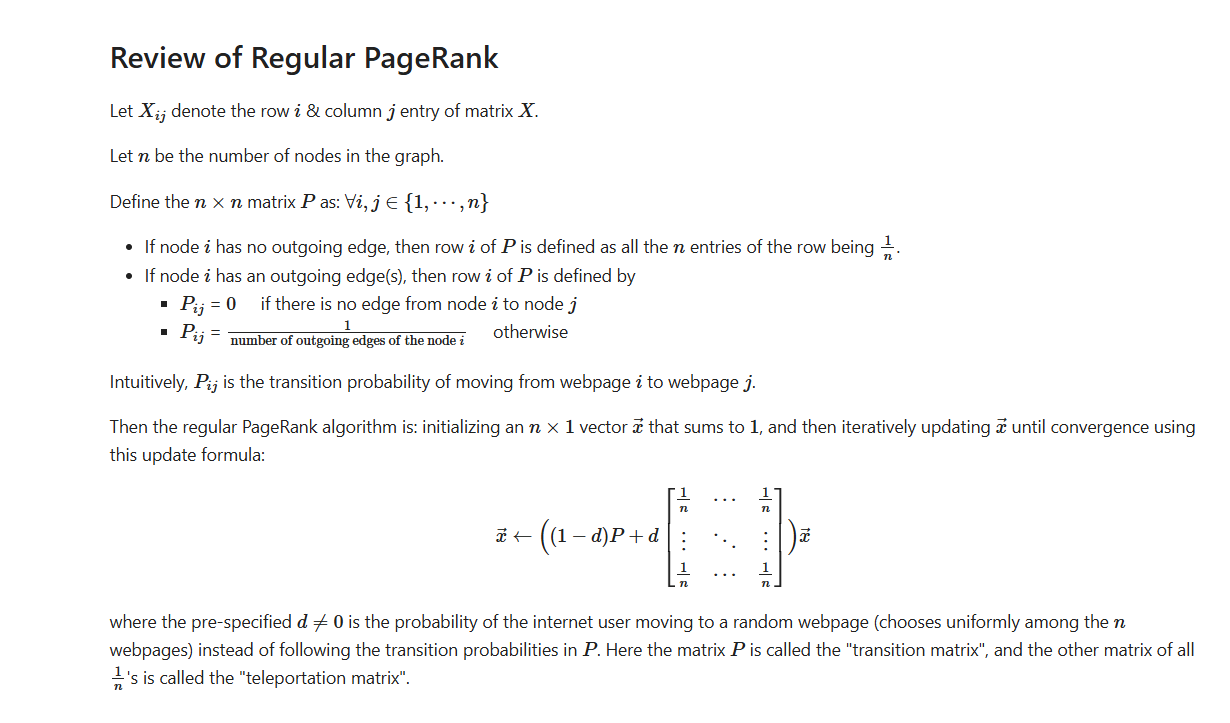

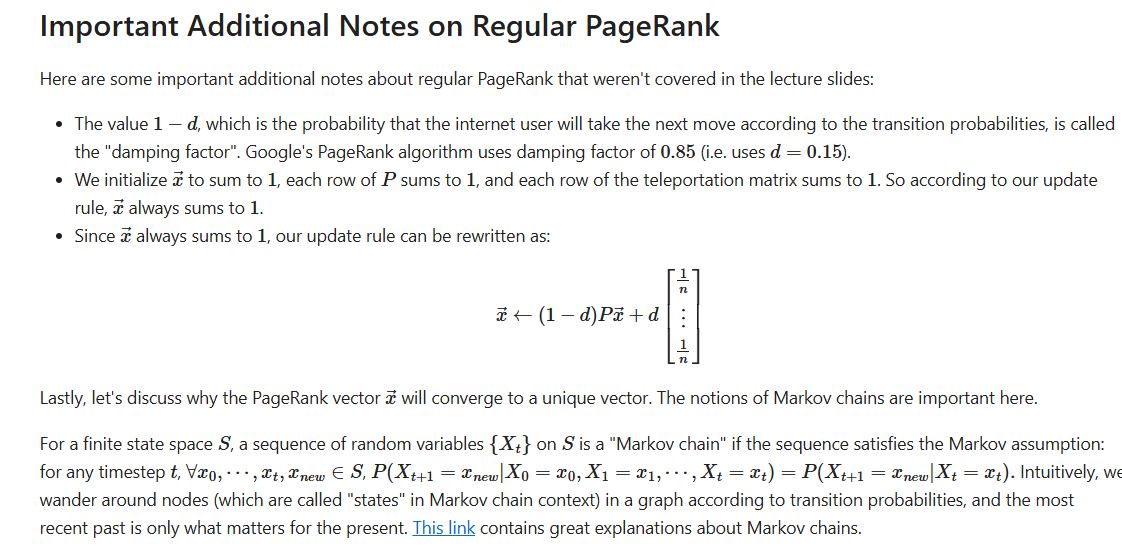

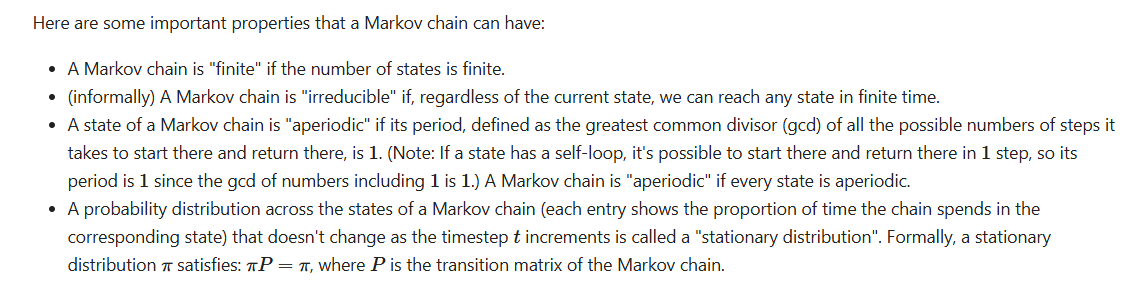

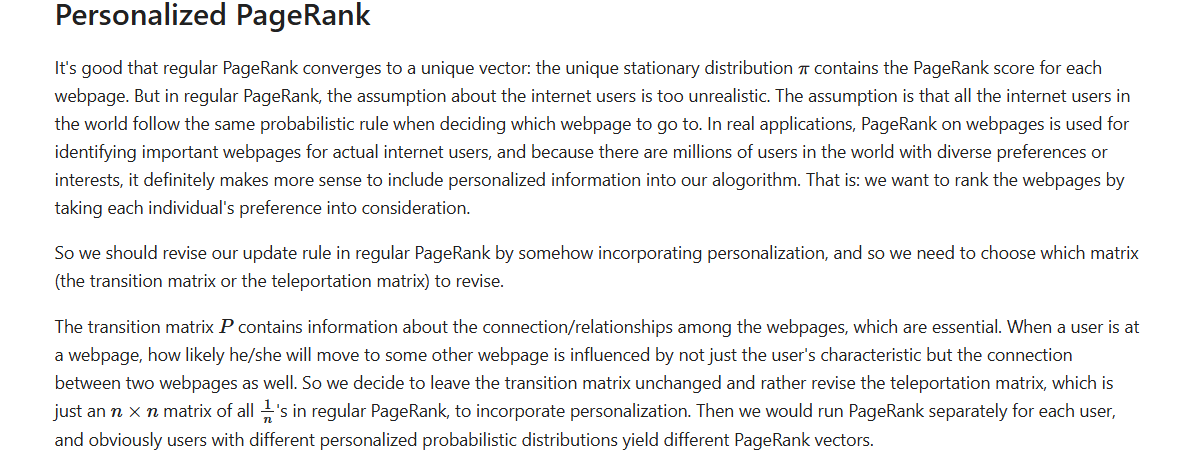

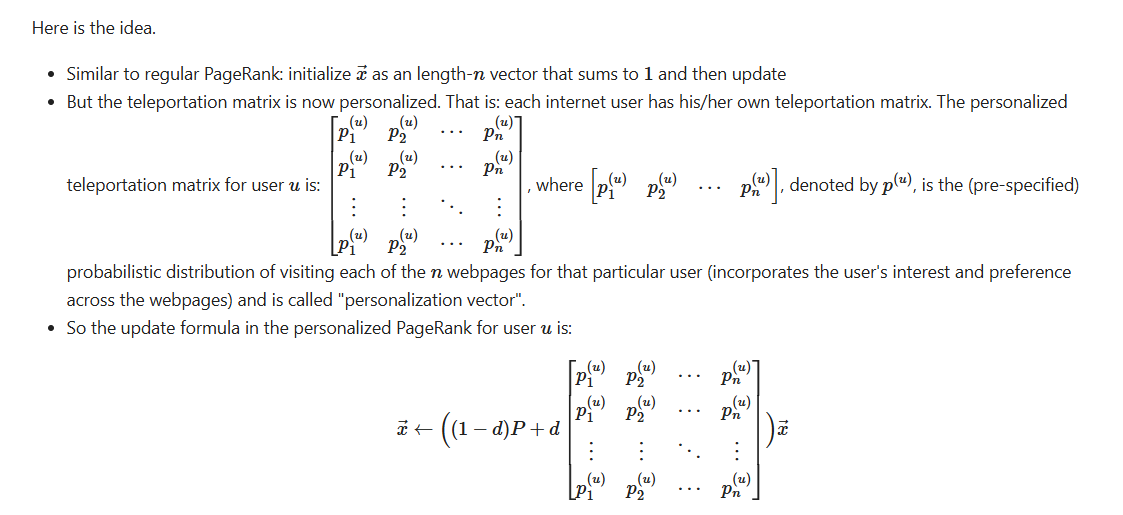

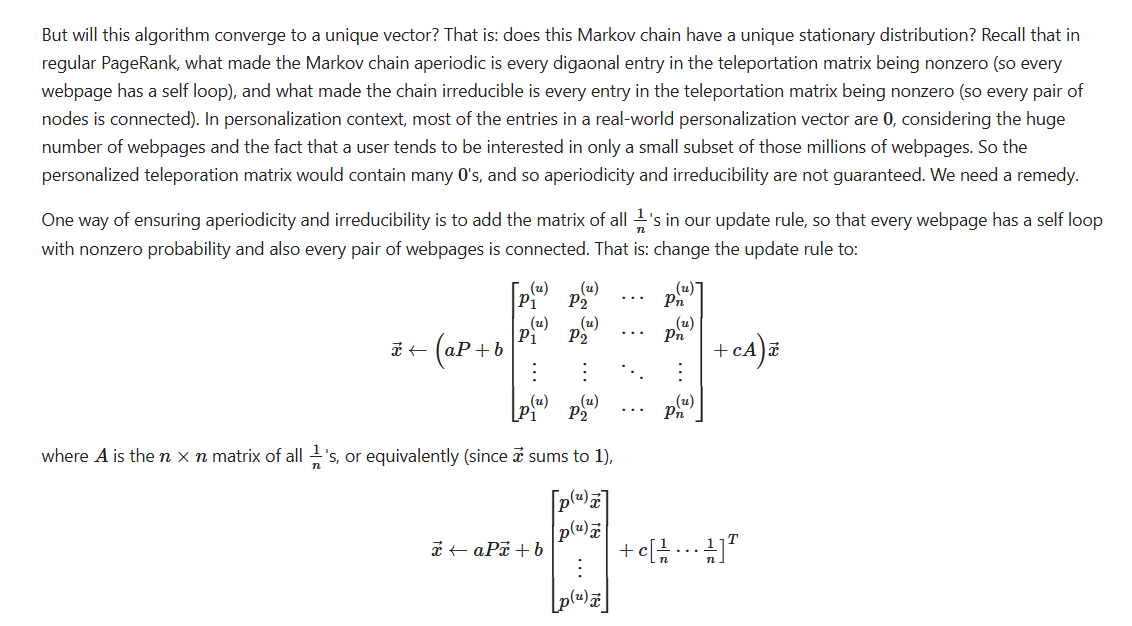

Example Code and Issue of Sparsity in PageRank
Let's examine some Python code for personalized PageRank on synthetically generated data (for the transition matrix and the personalization vectors). Another key point in PageRank algorithms (not just personalized PageRank) is storing the matrices as sparse matrices. There are over 1.5 billion websites on the World Wide Web (source), and on average, a webpage has 10 out-links (source). You can imagine how sparse the transition matrix would be. Also, a user definitely wouldn't be interested in all those websites, so a personalization vector would also be extremely sparse. So storing those huge matrices/vectors (since 
 is extremely large as just mentioned) as dense matrices (e.g. Numpy ndarrays) would cause a memory error. Instead, we should store them as sparse matrices offered by the Scipy package (link) which only store the nonzero values and handle memory much more efficiently. This issue is addressed in the code below.

In [56]:
# Loading libraries
import numpy as np
from scipy import sparse
from scipy.sparse.linalg import norm

In [58]:
# In our example, we set n = 80000 which is way smaller than the true number of webpages 
# in the world but is big enough to address the issue of sparsity. 
n = 80000

# Moreover, we consider four different users, 
# each with different interests, and thus different personalization vectors. Imagine a (very) simple scenario. 
# Our setting: 
# Assume that user 1 is only interested in (so has nonzero probability in the personalization vector) the first 20000 webpages, 
# user 2 only in the next 20000 pages, user 3 only in the next 20000, and user 4 only in the last 20000. 
# Moreover, each webpage has out-links to 10 other randomly chosen pages, each with transition probability 0.1
# so that the row sums to 1. 

# The following code chunks contain the code and detailed comments on running the personalized PageRank algorithm 
# for each of the four users.

In [59]:
# Instead, we store matrix as a sparse.lil_matrix offered by the Scipy library which efficiently uses memory by storing only the
# nonzero entries and also is more efficient when changing the matrix entries compared to other Scipy sparse matrix formats 
# like sparse.csr_matrix. 

# (Note: You might be wondering why not use csr_matrix and initialize by specifying the rows & columns & values for the
# nonzero entries. That approach is also problematic because specifying the rows and columns each take length 80000 Numpy arrays
# and cause memory error even before calling the sparse.csr_matrix() function to initialize. So although our approach here 
# is relatively slow as we loop through for filling up the nonzero entries, we use this approach since we can avoid memory error)

# Initialize the 80000 x 80000 sparse transition matrix as all 0's
transition_matrix = sparse.lil_matrix((n,n))

# Fill up nonzero entries by randomly selecting ten outlink pages for each webpage and assigning probability 0.1 
for i in range(0, n):
    outlink_pages = np.random.choice(range(0,n), 10, replace=False)
    # If the randomly chosen pages include itself, replace with some other page that wasn't selected
    if i in outlink_pages:
        done_replacing = False
        # Increment until we find a page that wasn't selected 
        # (When we reach 80000, we start from 0. The mod function takes care of this)
        j = i
        while (not done_replacing):
            j = (j+1) % n
            if (j not in outlink_pages):
                outlink_pages[np.where(outlink_pages==i)] = j
                done_replacing = True
    transition_matrix[i, outlink_pages] = 0.1
    
# We convert the transition matrix (currently sparse.lil_Matrix) into a sparse.csr_matrix
# which is more efficient in arithmetic operations compared to other Scipy's sparse matrix formats
transition_matrix = transition_matrix.tocsr()

In [61]:
# Now we create the personalization vector (length 80000) for each of the four users.
# As mentinoned before, we assume: user 1 is only interested in the first 20000 webpages,
# user 2 only in the next 20000 pages, user 3 only in the next 20000, and user 4 only in the last 20000.

# Again, to avoid memory error, we initialize the 1 x 80000 sparse lil matrix of all 0's
# and then fill in the nonzero entries

# Initialize the 1 x 80000 sparse personalization vector for each user
user1 = sparse.lil_matrix((1,n))
user2 = sparse.lil_matrix((1,n))
user3 = sparse.lil_matrix((1,n))
user4 = sparse.lil_matrix((1,n))

users = [user1, user2, user3, user4]

# Fill in the nonzero entries of the personalization vector for each user

for idx, vec in enumerate(users):
    rand = np.random.rand(1, 20000)
    rand /= np.sum(rand)

    start = idx * 20000
    vec[0, start:start + 20000] = rand
    
# Note after creating each personalized teleportation matrix, we convert it (currently in sparse.lil_matrix)
# in to sparse.csr_matrix which is more efficient for arithmetic operations compared to other scipy's sparse matrix formats


In [62]:
######## Personalized PageRank Algorithm for User 1 ##########

# Decide values of a,b,c. For this tutorial, let's use a = 0.8, b = 0.15, c = 0.05.
a = 0.8
b = 0.15
c = 0.05

# Initialize PageRank vector: 80000 x 1 vector of all 1/80000 's
# We also represent the PageRank vector as a sparse csr matrix so that every arithmetic operation result
# is stored as a sparse csr matrix throughout the algorithm... again dealing with sparsity issue & memory issue
user1_pagerank = sparse.csr_matrix(np.ones((n,1)) / n)

# Update the PageRank vector until convergence! Our convergence criterion is to see whether
# the magnitude of the difference of the PageRank vector after an update is 0

converged = False
teleport = c * sparse.csr_matrix(np.ones((n, 1)) / n)

while not converged:

    old_vec = user1_pagerank.copy()
    personal = b * sparse.csr_matrix(user1.dot(user1_pagerank)[0, 0] * np.ones((n, 1)))
    user1_pagerank = a * transition_matrix.dot(user1_pagerank) + personal + teleport

    diff_norm = norm(user1_pagerank - old_vec)
    print("magnitude of difference is :", diff_norm)

    converged = (diff_norm == 0)


magnitude of difference is : 4.791541927135544e-18
magnitude of difference is : 4.31238773442199e-18
magnitude of difference is : 4.31238773442199e-18
magnitude of difference is : 3.833233541708435e-18
magnitude of difference is : 4.791541927135544e-18
magnitude of difference is : 4.31238773442199e-18
magnitude of difference is : 3.354079348994881e-18
magnitude of difference is : 2.8749251562813265e-18
magnitude of difference is : 2.8749251562813265e-18
magnitude of difference is : 2.395770963567772e-18
magnitude of difference is : 1.9166167708542177e-18
magnitude of difference is : 2.395770963567772e-18
magnitude of difference is : 1.9166167708542177e-18
magnitude of difference is : 1.9166167708542177e-18
magnitude of difference is : 2.395770963567772e-18
magnitude of difference is : 9.583083854271088e-19
magnitude of difference is : 1.4374625781406633e-18
magnitude of difference is : 2.395770963567772e-18
magnitude of difference is : 9.583083854271088e-19
magnitude of difference is :

In [68]:
######## Personalized PageRank Algorithm for User 2 ##########

# Initialize PageRank vector: 80000 x 1 vector of all 1/80000 's
# We also represent the PageRank vector as a sparse csr matrix so that every arithmetic operation result
# is stored as a sparse csr matrix throughout the algorithm... again dealing with sparsity issue & memory issue
user2_pagerank = sparse.csr_matrix(np.ones((n,1)) / n)

# Update the PageRank vector until convergence! Our convergence criterion is to see whether
# the magnitude of the difference of the PageRank vector after an update is 0

converged = False
teleport = c * sparse.csr_matrix(np.ones((n, 1)) / n)

while not converged:

    old_vec2 = user2_pagerank.copy()
    personal = b * sparse.csr_matrix(user2.dot(user2_pagerank)[0, 0] * np.ones((n, 1)))
    user2_pagerank = a * transition_matrix.dot(user2_pagerank) + personal + teleport

    diff_norm = norm(user2_pagerank - old_vec2)
    print("magnitude of difference is :", diff_norm)

    converged = (diff_norm == 0)


magnitude of difference is : 4.791541927135544e-19
magnitude of difference is : 0.0


In [71]:
######## Personalized PageRank Algorithm for User 3 ##########

# Initialize PageRank vector: 80000 x 1 vector of all 1/80000 's
# We also represent the PageRank vector as a sparse csr matrix so that every arithmetic operation result
# is stored as a sparse csr matrix throughout the algorithm... again dealing with sparsity issue & memory issue
user3_pagerank = sparse.csr_matrix(np.ones((n,1)) / n)

# Update the PageRank vector until convergence! Our convergence criterion is to see whether
# the magnitude of the difference of the PageRank vector after an update is 0

converged = False
teleport = c * sparse.csr_matrix(np.ones((n, 1)) / n)

while not converged:

    old_vec3 = user3_pagerank.copy()
    personal = b * sparse.csr_matrix(user3.dot(user3_pagerank)[0, 0] * np.ones((n, 1)))
    user3_pagerank = a * transition_matrix.dot(user3_pagerank) + personal + teleport

    diff_norm = norm(user3_pagerank - old_vec3)
    print("magnitude of difference is :", diff_norm)

    converged = (diff_norm == 0)


magnitude of difference is : 1.4374625781406633e-18
magnitude of difference is : 4.791541927135544e-19
magnitude of difference is : 0.0


In [72]:
######## Personalized PageRank Algorithm for User 4 ##########

# Initialize PageRank vector: 80000 x 1 vector of all 1/80000 's
# We also represent the PageRank vector as a sparse csr matrix so that every arithmetic operation result
# is stored as a sparse csr matrix throughout the algorithm... again dealing with sparsity issue & memory issue
user4_pagerank = sparse.csr_matrix(np.ones((n,1)) / n)

# Update the PageRank vector until convergence! Our convergence criterion is to see whether
# the magnitude of the difference of the PageRank vector after an update is 0

converged = False
teleport = c * sparse.csr_matrix(np.ones((n, 1)) / n)

while not converged:

    old_vec4 = user4_pagerank.copy()
    personal = b * sparse.csr_matrix(user4.dot(user4_pagerank)[0, 0] * np.ones((n, 1)))
    user4_pagerank = a * transition_matrix.dot(user4_pagerank) + personal + teleport

    diff_norm = norm(user4_pagerank - old_vec4)
    print("magnitude of difference is :", diff_norm)

    converged = (diff_norm == 0)



magnitude of difference is : 2.8749251562813265e-18
magnitude of difference is : 1.9166167708542177e-18
magnitude of difference is : 2.395770963567772e-18
magnitude of difference is : 1.9166167708542177e-18
magnitude of difference is : 2.395770963567772e-18
magnitude of difference is : 9.583083854271088e-19
magnitude of difference is : 1.4374625781406633e-18
magnitude of difference is : 2.395770963567772e-18
magnitude of difference is : 4.791541927135544e-19
magnitude of difference is : 1.4374625781406633e-18
magnitude of difference is : 1.4374625781406633e-18
magnitude of difference is : 1.9166167708542177e-18
magnitude of difference is : 1.4374625781406633e-18
magnitude of difference is : 1.4374625781406633e-18
magnitude of difference is : 1.4374625781406633e-18
magnitude of difference is : 4.791541927135544e-19
magnitude of difference is : 9.583083854271088e-19
magnitude of difference is : 9.583083854271088e-19
magnitude of difference is : 1.9166167708542177e-18
magnitude of differe

To verify we have different converged PageRank vectors for the four users, we print, for each pair of the four vectors, the magnitude of the difference. Notice they are all nonzero, so indeed they're all different.

In [73]:

print("difference between pagerank of users 1 and 2:", norm(user1_pagerank - user2_pagerank))
print("difference between pagerank of users 1 and 3:", norm(user1_pagerank - user3_pagerank))
print("difference between pagerank of users 1 and 4:", norm(user1_pagerank - user4_pagerank))
print("difference between pagerank of users 2 and 3:", norm(user2_pagerank - user3_pagerank))
print("difference between pagerank of users 2 and 4:", norm(user2_pagerank - user4_pagerank))
print("difference between pagerank of users 3 and 4:", norm(user3_pagerank - user4_pagerank))

difference between pagerank of users 1 and 2: 6.229004505276208e-17
difference between pagerank of users 1 and 3: 6.468581601632985e-17
difference between pagerank of users 1 and 4: 9.343506757914311e-17
difference between pagerank of users 2 and 3: 2.395770963567772e-18
difference between pagerank of users 2 and 4: 3.114502252638104e-17
difference between pagerank of users 3 and 4: 2.874925156281326e-17


Finally, we show that if we put more weights on the personalized transportation matrix (i.e. use larger value of 
), the differences of the converged personalized PageRank vectors for the different users are larger than before because more personalization is incorporated.

In [ ]:
a = 0.1
b = 0.8
c = 0.05

# User1
user1_pagerank = sparse.csr_matrix(np.ones((n,1)) / n)

converged = False
teleport = c * sparse.csr_matrix(np.ones((n, 1)) / n)

while not converged:

    old_vec = user1_pagerank.copy()
    personal = b * sparse.csr_matrix(user1.dot(user1_pagerank)[0, 0] * np.ones((n, 1)))
    user1_pagerank = a * transition_matrix.dot(user1_pagerank) + personal + teleport

    diff_norm = norm(user1_pagerank - old_vec)

    converged = (diff_norm == 0)

#User2
user2_pagerank = sparse.csr_matrix(np.ones((n,1)) / n)

converged = False
teleport = c * sparse.csr_matrix(np.ones((n, 1)) / n)

while not converged:

    old_vec2 = user2_pagerank.copy()
    personal = b * sparse.csr_matrix(user2.dot(user2_pagerank)[0, 0] * np.ones((n, 1)))
    user2_pagerank = a * transition_matrix.dot(user2_pagerank) + personal + teleport

    diff_norm = norm(user2_pagerank - old_vec2)

    converged = (diff_norm == 0)

# User3
user3_pagerank = sparse.csr_matrix(np.ones((n,1)) / n)

converged = False
teleport = c * sparse.csr_matrix(np.ones((n, 1)) / n)

while not converged:

    old_vec3 = user3_pagerank.copy()
    personal = b * sparse.csr_matrix(user3.dot(user3_pagerank)[0, 0] * np.ones((n, 1)))
    user3_pagerank = a * transition_matrix.dot(user3_pagerank) + personal + teleport

    diff_norm = norm(user3_pagerank - old_vec3)

    converged = (diff_norm == 0)

# User4
user4_pagerank = sparse.csr_matrix(np.ones((n,1)) / n)

converged = False
teleport = c * sparse.csr_matrix(np.ones((n, 1)) / n)

while not converged:

    old_vec4 = user4_pagerank.copy()
    personal = b * sparse.csr_matrix(user4.dot(user4_pagerank)[0, 0] * np.ones((n, 1)))
    user4_pagerank = a * transition_matrix.dot(user4_pagerank) + personal + teleport

    diff_norm = norm(user4_pagerank - old_vec4)

    converged = (diff_norm == 0)

print("difference between pagerank of users 1 and 2:", norm(user1_pagerank - user2_pagerank))
print("difference between pagerank of users 1 and 3:", norm(user1_pagerank - user3_pagerank))
print("difference between pagerank of users 1 and 4:", norm(user1_pagerank - user4_pagerank))
print("difference between pagerank of users 2 and 3:", norm(user2_pagerank - user3_pagerank))
print("difference between pagerank of users 2 and 4:", norm(user2_pagerank - user4_pagerank))
print("difference between pagerank of users 3 and 4:", norm(user3_pagerank - user4_pagerank))

difference between pagerank of users 1 and 2: 6.540454730540018e-17
difference between pagerank of users 1 and 3: 1.260175526836648e-16
difference between pagerank of users 1 and 4: 1.7009973841331181e-16
difference between pagerank of users 2 and 3: 6.061300537826464e-17
difference between pagerank of users 2 and 4: 1.0469519110791164e-16
difference between pagerank of users 3 and 4: 4.4082185729647003e-17


**The differences have become larger compared to the previous part, which shows that the PageRank is now more personalized.**